# **Experiment Notebook**



In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *

In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.2'

---
## Student Information

In [4]:
# <Student to fill this section>
student_name = "Vedang Gosavi"
student_id = "26059271"
group_id = "12"

In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

In [7]:
# Do not modify this code
print_tile(size="h1", key='group_id', value=group_id)

---
## 0. Python Packages

In [8]:
# <Student to fill this section>
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna
import sklearn
import joblib

from at3_crypto.config import RAW_DATA_DIR, PROCESSED_DATA_DIR, MODELS_DIR
from at3_crypto.dataset import fetch_all, save_snapshot, load_latest_snapshot, SUPPORTED_TOKENS

RANDOM_STATE = 42
N_JOBS = 1             # parallel training crashes on this Windows setup
FORECAST_HORIZON = 7

np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)

for name, mod in [("pandas", pd), ("numpy", np), ("lightgbm", lgb),
                  ("optuna", optuna), ("scikit-learn", sklearn), ("joblib", joblib)]:
    print(f"{name:13} {mod.__version__}")

2026-10-23 02:28:51.709 | INFO     | at3_crypto.config:<module>:11 - PROJ_ROOT path is: C:\dev\36120-at3-group12-experiments


pandas        2.2.2
numpy         2.5.4
lightgbm      4.6.0
optuna        4.9.0
scikit-learn  1.6.1
joblib        1.5.3


---
## A. Project Description


In [9]:
# <Student to fill this section>
business_use_case_description = """
This project is part of a cloud-native Cryptocurrency Financial Intelligence Platform built for retail
cryptocurrency investors. My component is the Trading Opportunity Rating (TOR) service.

TOR forecasts, 7 days ahead, which of five opportunity categories a selected cryptocurrency will fall into:
Strong Sell, Sell, Hold, Buy or Strong Buy. The rating is derived from an Opportunity Score that combines
20-day momentum, short-term versus long-term trend (MA5/MA20), trading volume relative to its 20-day
average, and a penalty for high volatility.

The goal for the business is to turn raw, noisy market data into a single, easy-to-read signal that helps
users decide where to focus their attention in the coming week. Predictions are served through an
independent FastAPI microservice deployed on Render and displayed in a shared Streamlit application,
together with a confidence score and feature importance so users can judge how much to trust each rating.
"""

In [10]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [11]:
# <Student to fill this section>
business_objectives = """
Objectives:
1. Predict the TOR class 7 days ahead for the supported cryptocurrencies using a LightGBM multiclass model
   tuned with Optuna.
2. Outperform two simple baselines on a time-ordered hold-out test set, measured by macro F1 and balanced
   accuracy: (a) always predicting the most frequent class, and (b) a persistence baseline that assumes the
   class in 7 days will equal today's class.
3. Provide a confidence score with every prediction so users can tell strong signals from weak ones.
4. Keep the service operational even when feature APIs from other team members are unavailable.

Impact of accurate results:
- Users get an early, interpretable view of where momentum, trend and volume are heading, helping them
  prioritise research, manage risk and avoid reacting late to market moves.
- A trustworthy signal increases user engagement and the credibility of the platform.

Impact of incorrect results:
- A false Buy or Strong Buy before a decline can lead users into losses; this is the most costly error.
- A false Sell or Strong Sell before a rise leads to missed opportunities or premature exits.
- Errors between distant classes (e.g. Strong Sell predicted as Strong Buy) are far more harmful than errors
  between neighbouring classes (e.g. Hold predicted as Buy), so evaluation should look beyond plain accuracy.
- Repeated confident but wrong ratings damage user trust and expose the platform to reputational and
  regulatory risk, since Buy/Sell labels can be perceived as financial advice.
"""

In [12]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [13]:
# <Student to fill this section>
stakeholders_expectations_explanations = """
How the results will be used:
The TOR prediction, its confidence score and feature importance are displayed on the TOR page of the
Streamlit application. The rating is intended as decision support for further research, not as an
instruction to trade. The /features endpoint (20-day volume moving average and Relative Volume) is also
consumed by the other prediction services in the platform.

Direct users:
- Retail cryptocurrency investors using the web app, who expect clear, timely ratings with an honest
  indication of uncertainty.
- Other team members' services (Asset Performance Index, Market Risk Index, Trend Category), which rely on
  my volume features and expect a stable, documented API contract.

Impacted stakeholders:
- The platform operator, whose reputation, legal exposure and user retention depend on the quality and
  responsible presentation of the ratings.
- Regulators such as ASIC, since Buy/Sell recommendations may be interpreted as general financial advice,
  requiring clear disclaimers.
- Inexperienced or financially vulnerable users, including people in under-banked or remote communities,
  who may over-rely on a simple label and are more exposed to losses and scams in crypto markets.
- The wider market: if many users act on the same signal at once, herd behaviour can amplify price moves.
"""

In [14]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## C. Data Understanding

### C.1   Load Raw Data


In [15]:
REFRESH_DATA = False   # set True to pull a fresh snapshot from Kraken

if REFRESH_DATA or not any(RAW_DATA_DIR.glob("kraken_ohlc_daily_*.csv")):
    df_new, failures = fetch_all()
    save_snapshot(df_new)
    print("Failed tokens:", failures or "none")

df_raw, raw_path = load_latest_snapshot()
print("Loaded:", raw_path.name)
print("Shape:", df_raw.shape)
print("\nDtypes:\n", df_raw.dtypes)
print("\nMissing values:\n", df_raw.isna().sum())
print("\nDuplicate (token, date) rows:", df_raw.duplicated(["token", "date"]).sum())

summary = df_raw.groupby("token").agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    zero_volume_days=("volume", lambda s: (s == 0).sum()),
)
summary["expected_days"] = (summary["last_date"] - summary["first_date"]).dt.days + 1
summary["missing_days"] = summary["expected_days"] - summary["rows"]
print("\nPer-token summary:")
display(summary)
df_raw.head()

Loaded: kraken_ohlc_daily_20261022.csv
Shape: (5760, 9)

Dtypes:
 token             object
date      datetime64[ns]
open             float64
high             float64
low              float64
close            float64
vwap             float64
volume           float64
count              int64
dtype: object

Missing values:
 token     0
date      0
open      0
high      0
low       0
close     0
vwap      0
volume    0
count     0
dtype: int64

Duplicate (token, date) rows: 0

Per-token summary:


,rows,first_date,last_date,zero_volume_days,expected_days,missing_days
token,,,,,,
BTC,720,2024-11-01,2026-10-21,0,720,0
DOGE,720,2024-11-01,2026-10-21,0,720,0
ETH,720,2024-11-01,2026-10-21,0,720,0
SOL,720,2024-11-01,2026-10-21,0,720,0
TRX,720,2024-11-01,2026-10-21,0,720,0
XLM,720,2024-11-01,2026-10-21,0,720,0
XMR,720,2024-11-01,2026-10-21,0,720,0
XRP,720,2024-11-01,2026-10-21,0,720,0


,token,date,open,high,low,close,vwap,volume,count
0,BTC,2024-11-01,70250.1,71576.0,68810.0,69490.1,69793.3,2425.491689,42761
1,BTC,2024-11-02,69490.1,69858.8,69060.0,69300.0,69444.7,803.138840,19256
2,BTC,2024-11-03,69300.9,69363.3,67483.7,68748.7,68293.5,2115.263489,35315
3,BTC,2024-11-04,68748.7,69430.6,66836.0,67783.3,68181.7,1544.561233,30935
4,BTC,2024-11-05,67787.8,70482.0,67481.4,69382.7,69409.3,2008.236272,30812


### C.2 Define Target variable

In [16]:
# <Student to fill this section>
from at3_crypto.features import build_features, TOR_MODEL_FEATURES, STUDENT_D_FEATURES
from at3_crypto.target import add_tor_target, TOR_LABELS, FORECAST_HORIZON

df_feat = build_features(df_raw)

print("Shape after feature engineering:", df_feat.shape)
print("\nTOR model inputs:", TOR_MODEL_FEATURES)
print("Features owned by Student D:", STUDENT_D_FEATURES)
print("\nNaN count per model input (expected: 19 to 20 warm-up rows per token):")
print(df_feat[TOR_MODEL_FEATURES + STUDENT_D_FEATURES].isna().sum())
display(df_feat.groupby("token")[TOR_MODEL_FEATURES].describe().T.round(4))

Shape after feature engineering: (5760, 22)

TOR model inputs: ['Return20', 'RelativeVolume', 'Volatility20', 'MA5', 'MA20']
Features owned by Student D: ['VolumeSMA20', 'RelativeVolume']

NaN count per model input (expected: 19 to 20 warm-up rows per token):
Return20          160
RelativeVolume    152
Volatility20      160
MA5                32
MA20              152
VolumeSMA20       152
RelativeVolume    152
dtype: int64


token                         BTC      DOGE        ETH       SOL       TRX  \
Return20       count     700.0000  700.0000   700.0000  700.0000  700.0000   
               mean        0.0059   -0.0110     0.0101   -0.0029    0.0236   
               std         0.1028    0.2306     0.1737    0.1677    0.1150   
               min        -0.3419   -0.4028    -0.4465   -0.4602   -0.4174   
               25%        -0.0462   -0.1477    -0.1011   -0.1145   -0.0263   
               50%        -0.0023   -0.0484    -0.0105   -0.0141    0.0090   
               75%         0.0637    0.0702     0.0951    0.1095    0.0567   
               max         0.4457    1.8480     0.6284    0.6018    1.4428   
RelativeVolume count     701.0000  701.0000   701.0000  701.0000  701.0000   
               mean        1.0099    0.9974     1.0204    1.0084    1.0033   
               std         0.6075    0.7228     0.5841    0.5626    0.6683   
               min         0.1371    0.0868     0.1721    0.1780    0.1325   
               25%         0.6014    0.5305     0.6209    0.6374    0.5724   
               50%         0.9052    0.8095     0.9021    0.8857    0.8642   
               75%         1.2623    1.2714     1.2685    1.2522    1.2464   
               max         4.4777    7.1693     4.7037    5.1994    7.6365   
Volatility20   count     700.0000  700.0000   700.0000  700.0000  700.0000   
               mean        0.0217    0.0422     0.0345    0.0381    0.0228   
               std         0.0077    0.0149     0.0115    0.0137    0.0362   
               min         0.0082    0.0142     0.0121    0.0131    0.0047   
               25%         0.0165    0.0319     0.0270    0.0296    0.0107   
               50%         0.0208    0.0423     0.0330    0.0372    0.0152   
               75%         0.0246    0.0503     0.0395    0.0429    0.0202   
               max         0.0498    0.0959     0.0620    0.0918    0.2313   
MA5            count     716.0000  716.0000   716.0000  716.0000  716.0000   
               mean    89578.0566    0.1747  2752.9267  141.9459    0.2936   
               std     16884.2313    0.0912   809.5701   51.5430    0.0427   
               min     59615.9200    0.0696  1555.9840   64.6940    0.1612   
               25%     76821.3500    0.0952  2049.9245   88.8230    0.2697   
               50%     89007.8900    0.1610  2567.4680  136.6680    0.2951   
               75%    103636.3750    0.2241  3280.8380  186.6695    0.3293   
               max    123096.9000    0.4434  4672.8780  254.1220    0.3684   
MA20           count     701.0000  701.0000   701.0000  701.0000  701.0000   
               mean    89775.9042    0.1749  2754.6843  141.7613    0.2945   
               std     16715.4327    0.0896   801.8323   50.7741    0.0397   
               min     61805.3850    0.0699  1622.4805   68.7260    0.1764   
               25%     76518.5100    0.0944  2091.3190   88.3515    0.2695   
               50%     89676.9900    0.1645  2567.9355  136.0785    0.2948   
               75%    104013.2050    0.2236  3294.4885  181.7065    0.3292   
               max    118313.5050    0.4209  4484.2585  239.9760    0.3579   

token                      XLM       XMR       XRP  
Return20       count  700.0000  700.0000  700.0000  
               mean     0.0750    0.0487    0.0554  
               std      0.5706    0.1549    0.3576  
               min     -0.3640   -0.5287   -0.4137  
               25%     -0.1272   -0.0361   -0.0967  
               50%     -0.0438    0.0411   -0.0241  
               75%      0.0679    0.1244    0.0643  
               max      4.8927    0.6003    2.8695  
RelativeVolume count  701.0000  701.0000  701.0000  
               mean     1.0372    1.0228    1.0161  
               std      0.7771    0.6670    0.7038  
               min      0.1345    0.1323    0.1633  
               25%      0.5292    0.6292    0.5832  
               50%      0.8283    0.8784    0.8574  
      

In [17]:
# <Student to fill this section>
target_definition_explanations = """
The target is the Trading Opportunity Rating (TOR), a 5-class rating of how attractive a cryptocurrency
looks 7 days from now. It is defined by the brief through an Opportunity Score (OS):

  M  = (Return20 + 0.20) / 0.40          Momentum Score: rewards positive 20-day price performance
  T  = MA5 / MA20                        Trend Score: short-term average relative to long-term average
  V  = MIN(RelativeVolume, 2) / 2        Volume Score: market participation, capped at twice normal volume
  R  = MIN(Volatility20 / 0.10, 1)       Volatility Penalty: discounts opportunities in unstable markets
  OS = 0.40*M + 0.30*T + 0.20*V - 0.10*R

OS is binned into Strong Sell (<0.20), Sell (0.20-0.40), Hold (0.40-0.60), Buy (0.60-0.80) and
Strong Buy (>=0.80).

Rationale for the business use case: retail investors want a single, interpretable signal that combines
the three things traders usually look at together (momentum, trend and volume confirmation) while
penalising risk. Predicting the rating 7 days ahead (t+7) turns it into a genuine forecasting problem:
the label for day t is computed from day t+7's values, while every input feature uses only information
available up to day t. This prevents data leakage and matches how the product is used, where a user
looks at today's data and wants to know what the rating will be next week.

Points to note: M is not clipped by the brief, so extreme 20-day returns push OS strongly in either
direction, and T stays close to 1 for most days, which shifts OS upwards by about 0.30. Both effects
shape the class distribution and are analysed in C.4.
"""

In [18]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable



In [19]:
# <Student to fill this section>
df_tor = add_tor_target(df_feat, horizon=FORECAST_HORIZON)
target_name = 'TOR'

print("Rows with a valid target:", df_tor[target_name].notna().sum(), "of", len(df_tor))
print("Rows without target (last 7 days per token + feature warm-up):", df_tor[target_name].isna().sum())

# Sanity check: TOR on day t must equal the class computed on day t+7
check = df_tor[df_tor["token"] == "BTC"][["date", "OS_t", "TOR_t", "OS_future", target_name, "TOR_label"]]
display(check.iloc[25:35])

Rows with a valid target: 5600 of 5760
Rows without target (last 7 days per token + feature warm-up): 160


,date,OS_t,TOR_t,OS_future,TOR,TOR_label
25,2024-11-26,0.805891,4,0.602819,3,Buy
26,2024-11-27,0.839122,4,0.757645,3,Buy
27,2024-11-28,0.756014,3,0.749046,3,Buy
28,2024-11-29,0.814904,4,0.674270,3,Buy
29,2024-11-30,0.692363,3,0.622913,3,Buy
30,2024-12-01,0.602978,3,0.641001,3,Buy
31,2024-12-02,0.635797,3,0.637902,3,Buy
32,2024-12-03,0.602819,3,0.594352,2,Hold
33,2024-12-04,0.757645,3,0.603933,3,Buy
34,2024-12-05,0.749046,3,0.567666,2,Hold


### C.4 Explore Target variable

Overall TOR class distribution:


,count,pct
TOR_label,,
Strong Sell,111,2.0
Sell,767,13.7
Hold,2546,45.5
Buy,1607,28.7
Strong Buy,569,10.2


Class distribution per token (% of rows):


TOR_label,Strong Sell,Sell,Hold,Buy,Strong Buy
token,,,,,
BTC,0.0,6.7,51.9,37.4,4.0
DOGE,3.4,26.4,40.1,18.1,11.9
ETH,3.0,14.0,44.9,25.3,12.9
SOL,3.4,17.1,41.4,27.1,10.9
TRX,0.1,1.7,50.6,43.6,4.0
XLM,2.0,22.4,43.1,20.6,11.9
XMR,2.7,6.4,39.9,38.3,12.7
XRP,1.1,14.7,51.9,19.1,13.1


Average contribution of each OS component:


,mean,std,min,max
0.40*M,0.227,0.279,-0.329,5.093
0.30*T,0.301,0.024,0.227,0.583
0.20*V,0.096,0.049,0.009,0.200
-0.10*R,-0.034,0.017,-0.100,-0.005


Persistence (TOR_t == TOR_t+7) agreement: 0.513

Transition matrix, today's class (rows) vs class in 7 days (columns), % of row:


TOR_label,Strong Sell,Sell,Hold,Buy,Strong Buy
TOR_t,,,,,
Strong Sell,32.4,48.6,12.6,6.3,0.0
Sell,6.6,40.4,46.1,6.6,0.4
Hold,0.9,13.1,59.2,22.2,4.6
Buy,0.1,3.8,37.7,48.3,10.1
Strong Buy,0.4,3.7,15.8,37.3,42.8


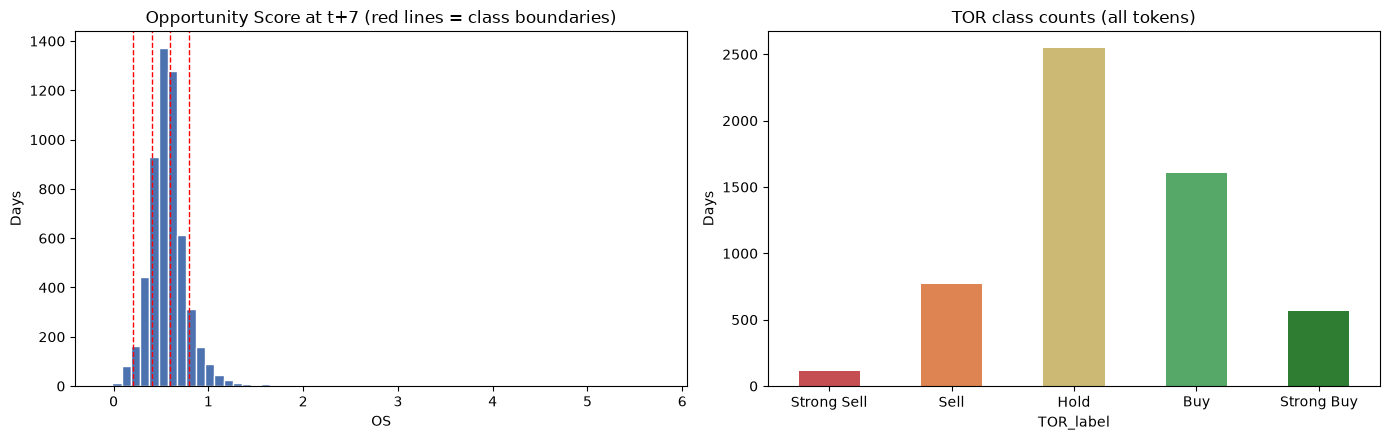

In [20]:
# <Student to fill this section>
from at3_crypto.config import FIGURES_DIR

labelled = df_tor.dropna(subset=[target_name]).copy()
labelled[target_name] = labelled[target_name].astype(int)

# 1. Overall class distribution
counts = labelled["TOR_label"].value_counts().reindex(TOR_LABELS, fill_value=0)
dist = pd.DataFrame({"count": counts, "pct": (counts / counts.sum() * 100).round(1)})
print("Overall TOR class distribution:")
display(dist)

# 2. Class distribution per token (%)
print("Class distribution per token (% of rows):")
display((pd.crosstab(labelled["token"], labelled["TOR_label"], normalize="index") * 100)
        .reindex(columns=TOR_LABELS, fill_value=0).round(1))

# 3. Average contribution of each OS component
comp = pd.DataFrame({
    "0.40*M": 0.40 * (labelled["Return20"] + 0.20) / 0.40,
    "0.30*T": 0.30 * labelled["MA5"] / labelled["MA20"],
    "0.20*V": 0.20 * labelled["RelativeVolume"].clip(upper=2) / 2,
    "-0.10*R": -0.10 * (labelled["Volatility20"] / 0.10).clip(upper=1),
})
print("Average contribution of each OS component:")
display(comp.describe().T[["mean", "std", "min", "max"]].round(3))

# 4. Persistence check: how often is the class in 7 days the same as today's class?
both = labelled.dropna(subset=["TOR_t"])
persistence_acc = (both["TOR_t"].astype(int) == both[target_name]).mean()
print(f"Persistence (TOR_t == TOR_t+7) agreement: {persistence_acc:.3f}")
print("\nTransition matrix, today's class (rows) vs class in 7 days (columns), % of row:")
display((pd.crosstab(both["TOR_t"].astype(int).map(dict(enumerate(TOR_LABELS))),
                     both["TOR_label"], normalize="index") * 100)
        .reindex(index=TOR_LABELS, columns=TOR_LABELS).round(1))

# 5. Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(labelled["OS_future"], bins=60, color="#4C72B0", edgecolor="white")
for b in [0.20, 0.40, 0.60, 0.80]:
    axes[0].axvline(b, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Opportunity Score at t+7 (red lines = class boundaries)")
axes[0].set_xlabel("OS")
axes[0].set_ylabel("Days")

dist["count"].plot.bar(ax=axes[1], color=["#C44E52", "#DD8452", "#CCB974", "#55A868", "#2E7D32"])
axes[1].set_title("TOR class counts (all tokens)")
axes[1].set_ylabel("Days")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tor_target_distribution.png", dpi=150)
plt.show()

In [21]:
# <Student to fill this section>
target_distribution_explanations = """
After removing the 20-day feature warm-up and the last 7 days of each token (no future label available),
5,544 labelled rows remain across 8 tokens (693 per token).

1. Class imbalance. The distribution is: Strong Sell 111 (2.0%), Sell 767 (13.7%), Hold 2,546 (45.5%),
   Buy 1,607 (28.7%), Strong Buy 569 (10.2%). The majority-to-minority ratio is about 23:1. A model that
   always predicts Hold would reach 45.5% accuracy, so accuracy alone is misleading. Macro F1 and balanced
   accuracy will be used, and class weighting will be tested during training.

2. Built-in upward shift. The trend term 0.30*T contributes 0.301 on average with a standard deviation of
   only 0.024, because MA5/MA20 rarely moves far from 1. It therefore acts as an almost constant +0.30.
   Combined with the average momentum (0.227) and volume (0.096) terms, the typical OS sits near 0.59,
   right at the Hold/Buy boundary, which explains why Buy (28.7%) is twice as frequent as Sell (13.7%).

3. Momentum dominates. 0.40*M has a standard deviation of 0.279, more than ten times larger than the other
   terms. The volatility penalty is small (mean -0.034, never below -0.10), so it rarely changes the class.
   Because the brief does not clip M, extreme 20-day rallies (e.g. XLM +489%) produce OS values above 5,
   creating a long right tail. These are genuine market events, not data errors, and they all fall in
   Strong Buy, so the class label is unaffected by how extreme they are.

4. Differences between tokens. Low-volatility assets rarely reach Strong Sell (BTC 0.0%, TRX 0.1%), while
   DOGE (26.4% Sell) and XLM (22.4% Sell) spend more time in negative classes. A single pooled model must
   therefore rely on scale-free features (returns, ratios, volatility) rather than raw prices.

5. Persistence and ordinal structure. The class in 7 days equals today's class 51.3% of the time, and most
   changes move to a neighbouring class (e.g. Hold to Buy 22.2%), while a jump from Strong Sell to Strong
   Buy never occurs. This gives a stronger baseline than the majority class (51.3% vs 45.5%) that the model
   must beat, and shows the classes are ordered: confusing Hold with Buy is far less harmful than confusing
   Strong Sell with Strong Buy. Evaluation will therefore also report within-one-class accuracy.

Limitations: Strong Sell has only 111 examples and is concentrated in market sell-offs, so it is likely to
be under-represented in some time periods of the train/validation/test split. The thresholds and weights
of the OS are fixed by the brief and were not designed around crypto return distributions, which is why
the classes are unevenly populated.
"""

In [22]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `\<put feature name here\>`

=== RelativeVolume ===
count    5552.0000
mean        1.0157
std         0.6669
min         0.0868
25%         0.5870
50%         0.8729
75%         1.2577
max         7.7319
Skewness: 2.77

Spearman correlation with OS at t+7: 0.145
Spearman correlation with TOR class:  0.137

Spearman correlation with OS at t+7, per token:
token
BTC     0.110
DOGE    0.101
ETH     0.092
SOL     0.115
TRX     0.141
XLM     0.214
XMR     0.168
XRP     0.170

Median by TOR class:
TOR_label
Strong Sell    0.8067
Sell           0.8095
Hold           0.8149
Buy            0.9375
Strong Buy     1.0546


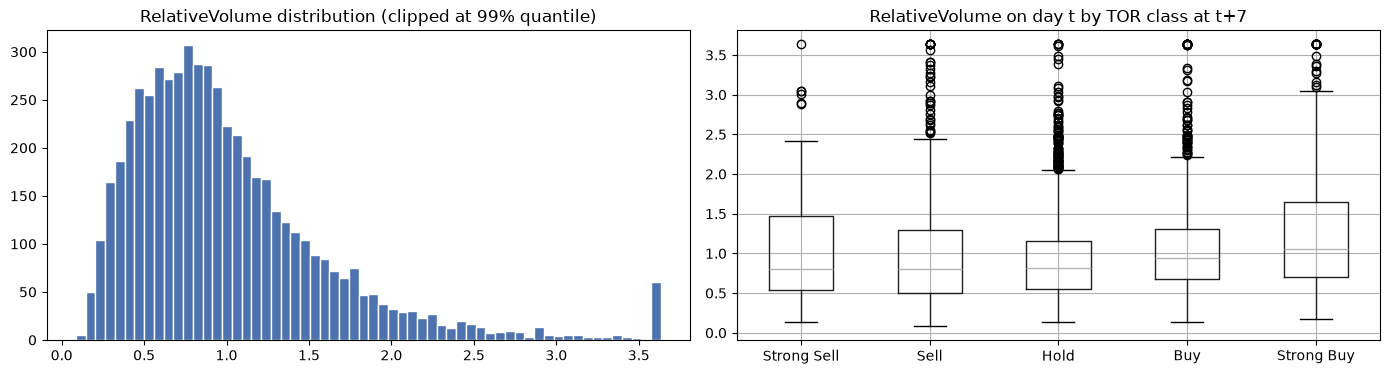

In [23]:
# <Student to fill this section>
def explore_feature(df, col, clip_q=None):
    """Distribution, per-token stats and relationship with the 7-day-ahead target."""
    data = df.dropna(subset=[col, target_name]).copy()
    print(f"=== {col} ===")
    print(data[col].describe().round(4).to_string())
    print(f"Skewness: {data[col].skew():.2f}")

    rho_os = data[[col, "OS_future"]].corr(method="spearman").iloc[0, 1]
    rho_cls = data[[col, target_name]].astype(float).corr(method="spearman").iloc[0, 1]
    print(f"\nSpearman correlation with OS at t+7: {rho_os:.3f}")
    print(f"Spearman correlation with TOR class:  {rho_cls:.3f}")

    print("\nSpearman correlation with OS at t+7, per token:")
    print(data.groupby("token")[[col, "OS_future"]]
          .apply(lambda g: g.corr(method="spearman").iloc[0, 1]).round(3).to_string())

    print("\nMedian by TOR class:")
    print(data.groupby("TOR_label")[col].median().reindex(TOR_LABELS).round(4).to_string())

    plot_data = data[col]
    if clip_q is not None:
        plot_data = plot_data.clip(upper=plot_data.quantile(clip_q))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].hist(plot_data, bins=60, color="#4C72B0", edgecolor="white")
    axes[0].set_title(f"{col} distribution" + (f" (clipped at {clip_q:.0%} quantile)" if clip_q else ""))
    data.assign(_v=plot_data).boxplot(column="_v", by="TOR_label", ax=axes[1],
                                      positions=[TOR_LABELS.index(c) for c in sorted(data["TOR_label"].unique())])
    axes[1].set_xticks(range(len(TOR_LABELS)), TOR_LABELS)
    axes[1].set_title(f"{col} on day t by TOR class at t+7")
    axes[1].set_xlabel("")
    plt.suptitle("")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"eda_{col}.png", dpi=150)
    plt.show()

explore_feature(df_tor, "RelativeVolume", clip_q=0.99)

In [24]:
# <Student to fill this section>
feature_1_insights = """
RelativeVolume (owned by Student D) = Volume_t / SMA20(Volume) compares today's trading activity with
its 20-day average. It is scale-free, so it is comparable across tokens even though raw volume differs
by orders of magnitude (and Kraken reports volume in coin units, not USD).

Distribution: 5,552 non-missing labelled rows, mean 1.02, median 0.87, range 0.09 to 7.73, skewness 2.77.
Most days trade slightly below average volume, punctuated by short bursts of very high activity. These
spikes are real market events (news, liquidations, listings), not errors, so they are kept. No log
transform is needed because tree-based models split on the order of values, not their distance.

Relationship with the target: the Spearman correlation with OS at t+7 is weak but consistently positive
(0.145 pooled, from 0.092 for ETH to 0.214 for XLM). The box plot shows a non-linear, U-shaped pattern:
volume is highest and most dispersed before Strong Buy (median 1.05) and also elevated and wide before
Strong Sell, while Hold has the lowest, tightest volume (median 0.81). High volume signals a large move
in either direction, while low volume signals continuation. A linear correlation understates this, but
a gradient-boosted tree model such as LightGBM can capture it, supporting the choice of algorithm.

Limitations: volume alone does not reveal the direction of the next move, so RelativeVolume is useful
mainly in combination with momentum (Return20). Volume is exchange-specific (Kraken only), which is
acceptable because the ratio cancels the scale, but it may differ from aggregated market volume.
"""

In [25]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `Add blockquote`





=== Return20 ===
count    5544.0000
mean        0.0267
std         0.2791
min        -0.5287
25%        -0.0852
50%        -0.0064
75%         0.0807
max         4.8927
Skewness: 7.85

Spearman correlation with OS at t+7: 0.575
Spearman correlation with TOR class:  0.550

Spearman correlation with OS at t+7, per token:
token
BTC     0.570
DOGE    0.575
ETH     0.691
SOL     0.633
TRX     0.529
XLM     0.436
XMR     0.550
XRP     0.475

Median by TOR class:
TOR_label
Strong Sell   -0.2470
Sell          -0.1360
Hold          -0.0275
Buy            0.0516
Strong Buy     0.1630


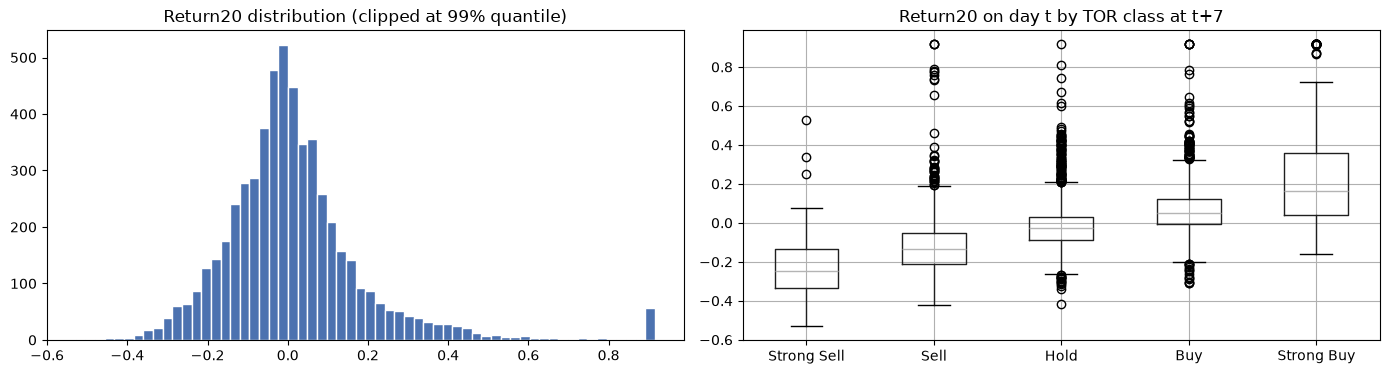

In [26]:
# <Student to fill this section>
explore_feature(df_tor, "Return20", clip_q=0.99)

In [27]:
# <Student to fill this section>
feature_2_insights = """
Return20 (owned by Student A) = (Close_t - Close_t-20) / Close_t-20 measures 20-day price momentum.
It is scale-free and directly comparable across tokens.

Distribution: 5,544 labelled rows, mean +2.7%, median -0.6%, range -52.9% to +489.3%, skewness 7.85.
Most 20-day returns fall within roughly -9% to +8% (interquartile range), but a small number of explosive
rallies (XLM, XRP, DOGE, TRX) create an extreme right tail that pulls the mean well above the median.
These are genuine market events, not data errors, so they are kept. Tree-based models are robust to
such outliers because they split on value order rather than magnitude, so no transformation is applied.

Relationship with the target: Return20 is the strongest single predictor, with a Spearman correlation of
0.575 with OS at t+7 (0.550 with the TOR class). The relationship holds for every token, from 0.436 (XLM)
to 0.691 (ETH). The median Return20 rises monotonically across classes: Strong Sell about -25%, Sell -13.6%,
Hold -2.8%, Buy +5.2%, Strong Buy +16.3%. However, the interquartile ranges of neighbouring
classes overlap substantially (for example Sell and Hold, Hold and Buy), so Return20 alone cannot
separate adjacent classes and the other features are needed to refine the boundaries. Most model
errors are therefore expected between neighbouring classes rather than distant ones.

Two reasons explain the strength of the relationship: momentum (M) has by far the largest weight and
variance in the Opportunity Score, and the 20-day windows on day t and day t+7 share 13 days of returns,
so today's momentum carries directly into next week's score.

Limitations: this persistence means the model will be good at predicting continuation but weaker at
anticipating sudden reversals, which are exactly the moments that matter most to investors. The weaker
correlation for XLM (0.436) and XRP (0.475) reflects their large, short-lived spikes, which reverse
quickly and make their momentum less persistent.
"""

In [28]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `Volatility20`


=== Volatility20 ===
count    5544.0000
mean        0.0351
std         0.0218
min         0.0047
25%         0.0220
50%         0.0313
75%         0.0426
max         0.2313
Skewness: 3.76

Spearman correlation with OS at t+7: -0.200
Spearman correlation with TOR class:  -0.181

Spearman correlation with OS at t+7, per token:
token
BTC    -0.144
DOGE   -0.165
ETH    -0.136
SOL    -0.158
TRX    -0.278
XLM    -0.073
XMR    -0.268
XRP    -0.074

Median by TOR class:
TOR_label
Strong Sell    0.0575
Sell           0.0417
Hold           0.0297
Buy            0.0276
Strong Buy     0.0340


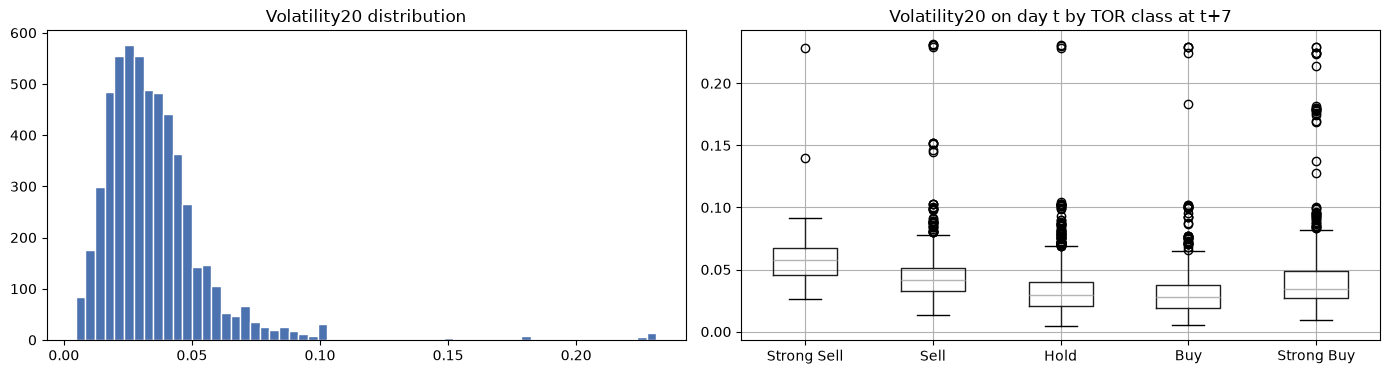

In [29]:
# <Student to fill this section>
explore_feature(df_tor, "Volatility20")

In [30]:
# <Student to fill this section>
feature_n_insights = """
Volatility20 (owned by Student C) = standard deviation of the last 20 daily returns. It measures how
turbulent the market has been over the past month and is scale-free across tokens.

Distribution: 5,544 labelled rows, mean 3.5%, median 3.1%, interquartile range 2.2% to 4.3%, maximum 23.1%,
skewness 3.76. Volatility differs strongly by asset: BTC and TRX are the calmest, while DOGE, XLM and SOL
are the most volatile. The brief caps the penalty at Volatility20 = 10% (R = MIN(Volatility20 / 0.10, 1)),
but this cap only applies on rare extreme days, so R almost always varies continuously. Extreme values
come from genuine market shocks and are kept; no transformation is needed for tree-based models.

Relationship with the target: the Spearman correlation with OS at t+7 is -0.200 (-0.181 with the TOR
class) and is negative for every token, strongest for TRX (-0.278) and XMR (-0.268) and weakest for
XLM and XRP (-0.073 and -0.074). The box plot shows a U-shaped pattern: median volatility is highest
before Strong Sell (about 5.8%), decreases through Sell (4.2%) and Hold (3.0%) to its minimum before Buy
(2.8%), and rises again before Strong Buy (3.4%). Calm markets tend to drift upwards, while turbulent
markets precede large moves, mostly sell-offs but also sharp rallies.

Insight: within the Opportunity Score, volatility only contributes a small penalty (average -0.034), but
as a predictor it carries regime information that goes beyond its weight in the formula, helping the
model separate Strong Sell from Sell and Strong Buy from Buy. This non-linear, U-shaped relationship is
another reason to use a tree-based model such as LightGBM.

Limitations: a 20-day window reacts slowly, so volatility jumps caused by a single shock persist in the
feature for 20 days after the event, and early warning of a new shock is limited.
"""

In [31]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

### C.n Explore Feature of Interest `MA5 and MA20 (raw vs MA5/MA20 ratio)`
> You can add more cells related to other feeatures in this section

Spearman correlation with OS at t+7, pooled across all tokens:
  MA5        0.094
  MA20       0.063
  MA_ratio   0.665

Median MA20 per token (shows the scale problem):
token
DOGE        0.1653
XLM         0.2505
TRX         0.2936
XRP         2.1120
SOL       136.1600
XMR       327.3800
ETH      2568.1045
BTC     89794.5425
=== MA_ratio ===
count    5552.0000
mean        1.0022
std         0.0807
min         0.7575
25%         0.9622
50%         0.9977
75%         1.0312
max         1.9429
Skewness: 2.91

Spearman correlation with OS at t+7: 0.665
Spearman correlation with TOR class:  0.628

Spearman correlation with OS at t+7, per token:
token
BTC     0.655
DOGE    0.667
ETH     0.744
SOL     0.716
TRX     0.579
XLM     0.586
XMR     0.635
XRP     0.605

Median by TOR class:
TOR_label
Strong Sell    0.8800
Sell           0.9362
Hold           0.9875
Buy            1.0232
Strong Buy     1.0636


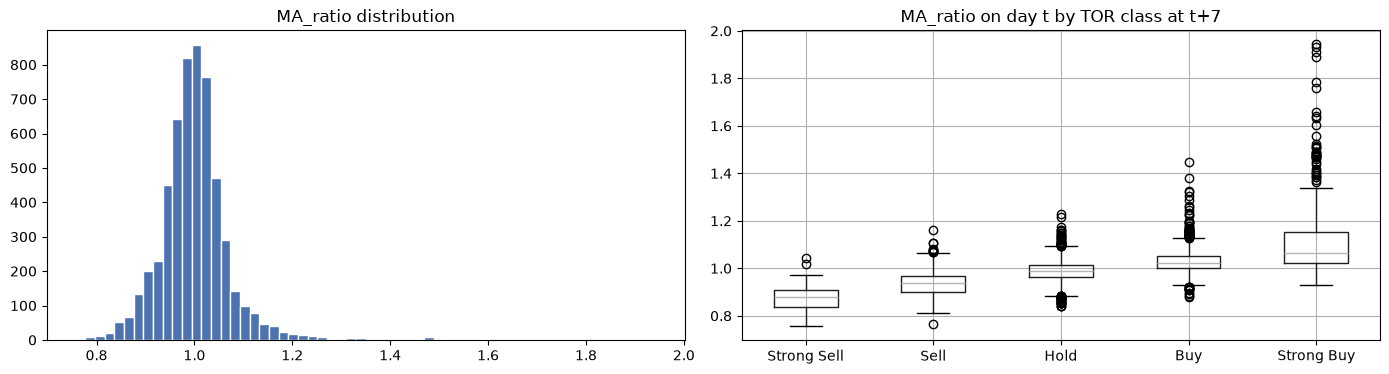

In [32]:
# <Student to fill this section>
df_tor["MA_ratio"] = df_tor["MA5"] / df_tor["MA20"]

data = df_tor.dropna(subset=["MA5", "MA20", target_name])
print("Spearman correlation with OS at t+7, pooled across all tokens:")
for col in ["MA5", "MA20", "MA_ratio"]:
    print(f"  {col:9} {data[[col, 'OS_future']].corr(method='spearman').iloc[0, 1]: .3f}")

print("\nMedian MA20 per token (shows the scale problem):")
print(data.groupby("token")["MA20"].median().sort_values().round(4).to_string())

explore_feature(df_tor, "MA_ratio")

In [33]:
# <Student to fill this section>
feature_4_insights = """
MA5 and MA20 (owned by Student B) are 5-day and 20-day simple moving averages of the closing price.
They are required inputs of the TOR model, and their ratio MA5/MA20 is the Trend Score (T) in the
Opportunity Score.

Scale problem: raw moving averages are expressed in each token's price units. The median MA20 ranges
from 0.17 USD (DOGE) to 89,795 USD (BTC), a factor of about 540,000. When the 8 tokens are pooled into
one model, the raw values mainly identify which token a row belongs to rather than its trend. As a
result, their Spearman correlations with OS at t+7 are almost zero (MA5 0.094, MA20 0.063).

Scale-free ratio: MA_ratio = MA5/MA20 (equivalent to TrendStrength + 1) removes the price scale and is
the strongest single predictor found in the EDA, with a Spearman correlation of 0.665 with OS at t+7,
higher than Return20 (0.575). Its distribution is centred on 1.0 (median 0.998, interquartile range
0.962 to 1.031, range 0.76 to 1.94, skewness 2.91). The median ratio rises evenly across classes:
Strong Sell about 0.88, Sell 0.936, Hold 0.988, Buy 1.023, Strong Buy 1.064, with less overlap between
neighbouring classes than Return20. It is strong because it captures smoothed recent momentum and is a
direct component of the future score, while MA20 on day t+7 shares 13 of its 20 days with MA20 on day t.

Decision: MA5 and MA20 are kept as model inputs because the brief requires them, and MA_ratio is added
as an engineered feature (section F). It is computed from MA5 and MA20 only, so it adds no new data
dependency on other services. Its added value is tested with cross-validation in section D.

Limitations: the ratio is close to 1 most of the time, so it changes slowly and reacts to trend reversals
with a delay of several days.
"""

In [34]:
# Do not modify this code
print_tile(size="h3", key='feature_4_insights', value=feature_4_insights)

---
## D. Feature Selection



### D.1 Approach "\<describe_approach_here\>"

---




Spearman correlation with OS at t+7 (pooled):


,rho
MA_ratio,0.664
OS_t,0.592
Return20,0.575
Volatility20,-0.200
RelativeVolume,0.145
MA5,0.094
MA20,0.064



Average within-token Spearman correlation between candidate features:


,Return20,RelativeVolume,Volatility20,MA5,MA20,MA_ratio,OS_t
Return20,1.00,0.11,-0.03,0.14,-0.03,0.81,0.93
RelativeVolume,0.11,1.00,-0.06,0.00,-0.03,0.12,0.40
Volatility20,-0.03,-0.06,1.00,0.17,0.17,-0.04,-0.09
MA5,0.14,0.00,0.17,1.00,0.97,0.13,0.12
MA20,-0.03,-0.03,0.17,0.97,1.00,-0.09,-0.05
MA_ratio,0.81,0.12,-0.04,0.13,-0.09,1.00,0.80
OS_t,0.93,0.40,-0.09,0.12,-0.05,0.80,1.00


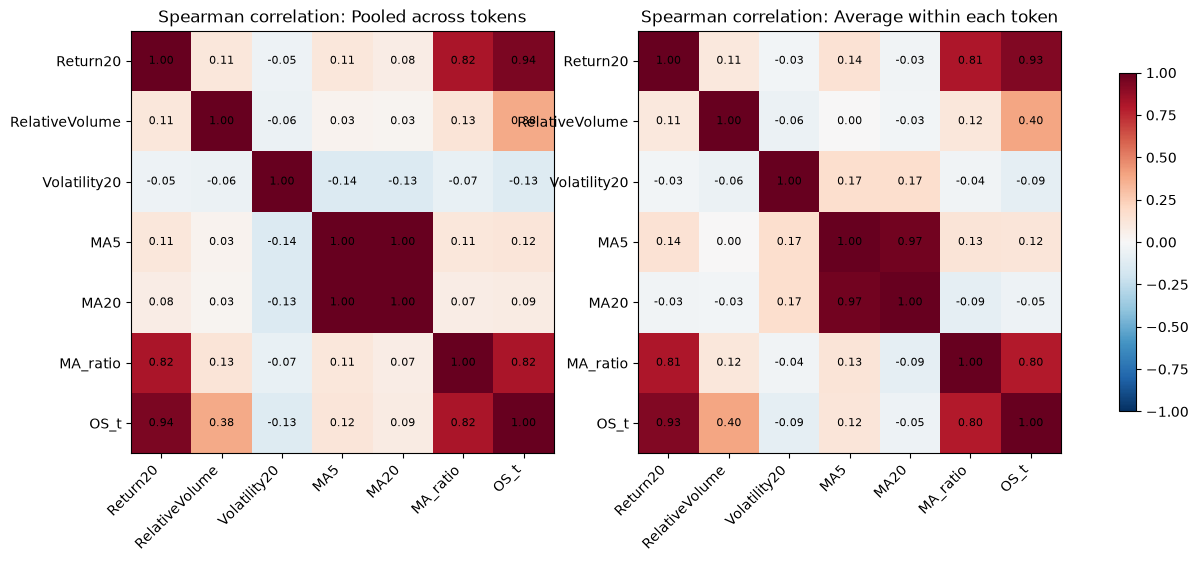

In [35]:
# <Student to fill this section>
df_tor["MA_ratio"] = df_tor["MA5"] / df_tor["MA20"]
CANDIDATES = TOR_MODEL_FEATURES + ["MA_ratio", "OS_t"]

corr_df = df_tor.dropna(subset=CANDIDATES + ["OS_future"])
spearman = corr_df[CANDIDATES + ["OS_future"]].corr(method="spearman")

print("Spearman correlation with OS at t+7 (pooled):")
display(spearman["OS_future"].drop("OS_future").sort_values(key=abs, ascending=False).round(3).to_frame("rho"))

per_token = [g[CANDIDATES].corr(method="spearman") for _, g in corr_df.groupby("token")]
within = sum(per_token) / len(per_token)
print("\nAverage within-token Spearman correlation between candidate features:")
display(within.loc[CANDIDATES, CANDIDATES].round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, mat, title in [(axes[0], spearman.loc[CANDIDATES, CANDIDATES], "Pooled across tokens"),
                       (axes[1], within.loc[CANDIDATES, CANDIDATES], "Average within each token")]:
    im = ax.imshow(mat.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(CANDIDATES)), CANDIDATES, rotation=45, ha="right")
    ax.set_yticks(range(len(CANDIDATES)), CANDIDATES)
    for i in range(len(CANDIDATES)):
        for j in range(len(CANDIDATES)):
            ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"Spearman correlation: {title}")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(FIGURES_DIR / "feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [36]:
# <Student to fill this section>
feature_selection_1_insights = """
Approach: Spearman rank correlation, computed (1) between each candidate feature and the Opportunity
Score at t+7, and (2) between the candidate features themselves, both pooled across tokens and averaged
within each token. Spearman was chosen because several features are heavily skewed with extreme values,
and it captures monotonic relationships without assuming linearity. The within-token view removes the
effect of price scale, which otherwise distorts the pooled correlations of raw prices.

Relevance to the target (Spearman with OS at t+7): MA_ratio 0.664, OS_t 0.592, Return20 0.575,
Volatility20 -0.200, RelativeVolume 0.145, MA5 0.094, MA20 0.064. The two engineered, scale-free features
(MA_ratio and OS_t) are as strong as or stronger than the best required input, while raw MA5 and MA20
carry almost no pooled signal.

Redundancy: MA5 and MA20 are almost identical (0.97 within token, 1.00 pooled), since both mainly encode
the price level. Return20, MA_ratio and OS_t form a highly correlated momentum group (0.80 to 0.93).
RelativeVolume and Volatility20 are nearly uncorrelated with every other feature (|rho| below 0.2 except
RelativeVolume with OS_t, 0.40, because volume is a direct component of OS), so they contribute
information that the momentum group does not contain, even though their individual correlation with the
target is weaker. Volume and volatility also showed U-shaped relationships with the target in the EDA,
which a single correlation coefficient understates.

Conclusion: correlation alone is not used to drop features. The five required inputs must stay to meet
the brief, and tree-based models such as LightGBM handle correlated features well. Instead, the
correlation results define the candidate feature sets that are compared with time-series
cross-validation in D.2, where the decision is based on predictive performance.
"""

In [37]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "\<describe_approach_here\>"


In [38]:
# <Student to fill this section>
from sklearn.metrics import f1_score, balanced_accuracy_score

model_df = df_tor.dropna(subset=TOR_MODEL_FEATURES + [target_name]).copy()
model_df[target_name] = model_df[target_name].astype(int)
model_df["token_code"] = model_df["token"].astype("category")

# Hold out the last 15% of dates as the final test set; feature selection never sees it
all_dates = np.sort(model_df["date"].unique())
TEST_START = pd.Timestamp(all_dates[int(len(all_dates) * 0.85)])
dev_df = model_df[model_df["date"] < TEST_START - pd.Timedelta(days=FORECAST_HORIZON)]
print(f"Development period: {dev_df['date'].min().date()} to {dev_df['date'].max().date()} "
      f"({dev_df['date'].nunique()} days). Test period (untouched) starts {TEST_START.date()}.")


def time_folds(df, n_folds=4, gap=FORECAST_HORIZON, min_train_frac=0.5):
    """Expanding-window folds by date. A 7-day gap stops training labels overlapping validation."""
    dates = np.sort(df["date"].unique())
    start = int(len(dates) * min_train_frac)
    fold_len = (len(dates) - start) // n_folds
    for k in range(n_folds):
        val_start = pd.Timestamp(dates[start + k * fold_len])
        val_end = (pd.Timestamp(dates[start + (k + 1) * fold_len - 1]) if k < n_folds - 1
                   else pd.Timestamp(dates[-1]))
        train = df[df["date"] < val_start - pd.Timedelta(days=gap)]
        val = df[(df["date"] >= val_start) & (df["date"] <= val_end)]
        yield train, val


def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=int), np.asarray(y_pred, dtype=int)
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=range(5), zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "accuracy": (y_true == y_pred).mean(),
        "within_one": (np.abs(y_true - y_pred) <= 1).mean(),
    }


def cv_evaluate(features, n_folds=4):
    rows = []
    for train, val in time_folds(dev_df, n_folds=n_folds):
        model = lgb.LGBMClassifier(objective="multiclass", n_estimators=300, learning_rate=0.05,
                                   num_leaves=15, class_weight="balanced",
                                   random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1)
        model.fit(train[features], train[target_name])
        rows.append(evaluate(val[target_name], model.predict(val[features])))
    return pd.DataFrame(rows).mean()


baseline_rows = []
for train, val in time_folds(dev_df):
    majority = train[target_name].mode()[0]
    baseline_rows.append({"set": "Baseline: majority class",
                          **evaluate(val[target_name], np.full(len(val), majority))})
    pers = val.dropna(subset=["TOR_t"])
    baseline_rows.append({"set": "Baseline: persistence (today's class)",
                          **evaluate(pers[target_name], pers["TOR_t"].astype(int))})
baselines = pd.DataFrame(baseline_rows).groupby("set", sort=False).mean()

FEATURE_SETS = {
    "1. Required 5 (raw MA5, MA20)": TOR_MODEL_FEATURES,
    "2. Required 5 + MA_ratio": TOR_MODEL_FEATURES + ["MA_ratio"],
    "3. Required 5 + MA_ratio + OS_t": TOR_MODEL_FEATURES + ["MA_ratio", "OS_t"],
    "4. Set 3 + token": TOR_MODEL_FEATURES + ["MA_ratio", "OS_t", "token_code"],
    "5. Scale-free only (no raw MAs)": ["Return20", "RelativeVolume", "Volatility20", "MA_ratio", "OS_t"],
}
results = pd.DataFrame({name: cv_evaluate(cols) for name, cols in FEATURE_SETS.items()}).T
comparison = pd.concat([baselines, results]).round(3)
print("\nTime-series cross-validation (4 expanding folds, 7-day gap), mean over folds:")
pd.set_option("display.width", 200)
display(comparison)

Development period: 2024-11-21 to 2026-06-25 (582 days). Test period (untouched) starts 2026-07-03.

Time-series cross-validation (4 expanding folds, 7-day gap), mean over folds:


,macro_f1,balanced_acc,accuracy,within_one
Baseline: majority class,0.134,0.213,0.502,0.940
Baseline: persistence (today's class),0.365,0.391,0.524,0.959
"1. Required 5 (raw MA5, MA20)",0.323,0.367,0.466,0.911
2. Required 5 + MA_ratio,0.336,0.381,0.491,0.930
3. Required 5 + MA_ratio + OS_t,0.341,0.391,0.496,0.926
4. Set 3 + token,0.333,0.385,0.482,0.918
5. Scale-free only (no raw MAs),0.346,0.393,0.513,0.933


In [39]:
# <Student to fill this section>
feature_selection_2_insights = """
Approach: wrapper-style feature selection by ablation. A default LightGBM classifier (300 trees, learning
rate 0.05, 15 leaves, balanced class weights) was trained on five candidate feature sets and compared
with time-series cross-validation: 4 expanding-window folds over the development period (2024-11-21 to
2026-06-25, 582 days), always training on the past and validating on the following period, with a 7-day
gap so no training label overlaps the validation window. The final 15% of dates (from 2026-07-03) are
held out and never used for selection. This approach was chosen because it measures each feature's
contribution to out-of-sample performance directly, and the time ordering mirrors how the model is used.

Results (mean macro F1 / balanced accuracy / accuracy / within-one-class accuracy):
  Majority-class baseline            0.134 / 0.213 / 0.502 / 0.940
  Persistence baseline (today's class) 0.365 / 0.391 / 0.524 / 0.959
  1. Required 5 (raw MA5, MA20)       0.323 / 0.367 / 0.466 / 0.911
  2. Required 5 + MA_ratio            0.336 / 0.381 / 0.491 / 0.930
  3. Required 5 + MA_ratio + OS_t     0.341 / 0.391 / 0.496 / 0.926
  4. Set 3 + token identifier         0.333 / 0.385 / 0.482 / 0.918
  5. Scale-free only (no raw MAs)     0.346 / 0.393 / 0.513 / 0.933

Findings:
- Adding the scale-free engineered features MA_ratio and OS_t improves macro F1 from 0.323 to 0.341,
  confirming the EDA finding that raw moving averages carry little pooled signal.
- Removing raw MA5 and MA20 gives the best score (0.346), but the gain over set 3 (0.005) is small, and
  the brief requires both as inputs. They are kept, which costs very little.
- Adding the token identifier lowers performance (0.333), so the model is kept token-agnostic. This
  helps it generalise across assets and keeps the API simple.
- No configuration beats the persistence baseline (0.365). The TOR class changes slowly (51% of classes
  persist over 7 days), and balanced class weights push predictions towards rare classes, lowering
  overall accuracy. This motivated an additional engineered feature that explicitly forecasts next
  week's score from the information already known today (D.3 and section F).
"""

In [40]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

   ### D.3 Approach "Forecast-window decomposition (projected score)"

In [41]:
# <Student to fill this section>
from at3_crypto.features import add_tor_engineered_features, TOR_ENGINEERED_FEATURES
from at3_crypto.target import score_to_class_id

df_tor = add_tor_engineered_features(df_tor, horizon=FORECAST_HORIZON)
df_tor["TOR_proj"] = score_to_class_id(df_tor["OS_proj"])

model_df = df_tor.dropna(subset=TOR_MODEL_FEATURES + [target_name]).copy()
model_df[target_name] = model_df[target_name].astype(int)
model_df["token_code"] = model_df["token"].astype("category")
dev_df = model_df[model_df["date"] < TEST_START - pd.Timedelta(days=FORECAST_HORIZON)]

proj = dev_df.dropna(subset=["OS_proj"])
print(f"Spearman correlation with OS at t+7: OS_proj {proj[['OS_proj', 'OS_future']].corr(method='spearman').iloc[0, 1]:.3f}, "
      f"OS_t {proj[['OS_t', 'OS_future']].corr(method='spearman').iloc[0, 1]:.3f}")

proj_rows = []
for train, val in time_folds(dev_df):
    v = val.dropna(subset=["TOR_proj"])
    proj_rows.append(evaluate(v[target_name], v["TOR_proj"].astype(int)))
baselines.loc["Baseline: flat-price projection (OS_proj class)"] = pd.DataFrame(proj_rows).mean()

REQ_PLUS = TOR_MODEL_FEATURES + ["MA_ratio", "OS_t"]
FEATURE_SETS_2 = {
    "3. Required 5 + MA_ratio + OS_t": REQ_PLUS,
    "6. Set 3 + OS_proj": REQ_PLUS + ["OS_proj"],
    "7. Set 3 + OS_proj + Return13": REQ_PLUS + ["OS_proj", "Return13"],
}
results_2 = pd.DataFrame({name: cv_evaluate(cols) for name, cols in FEATURE_SETS_2.items()}).T


def cv_evaluate_unweighted(features, n_folds=4):
    rows = []
    for train, val in time_folds(dev_df, n_folds=n_folds):
        model = lgb.LGBMClassifier(objective="multiclass", n_estimators=300, learning_rate=0.05,
                                   num_leaves=15, random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1)
        model.fit(train[features], train[target_name])
        rows.append(evaluate(val[target_name], model.predict(val[features])))
    return pd.DataFrame(rows).mean()


results_2.loc["8. Set 7 without class weights"] = cv_evaluate_unweighted(REQ_PLUS + ["OS_proj", "Return13"])

comparison_2 = pd.concat([baselines, results_2]).round(3)
print("\nTime-series cross-validation (4 expanding folds, 7-day gap), mean over folds:")
display(comparison_2)

Spearman correlation with OS at t+7: OS_proj 0.758, OS_t 0.598

Time-series cross-validation (4 expanding folds, 7-day gap), mean over folds:


,macro_f1,balanced_acc,accuracy,within_one
Baseline: majority class,0.134,0.213,0.502,0.940
Baseline: persistence (today's class),0.365,0.391,0.524,0.959
Baseline: flat-price projection (OS_proj class),0.428,0.433,0.607,0.982
3. Required 5 + MA_ratio + OS_t,0.341,0.391,0.496,0.926
6. Set 3 + OS_proj,0.372,0.423,0.536,0.947
7. Set 3 + OS_proj + Return13,0.369,0.414,0.533,0.947
8. Set 7 without class weights,0.373,0.396,0.550,0.958


In [42]:
# <Student to fill this section>
feature_selection_3_insights = """
Approach: forecast-window decomposition. Every 20-day window used by the target on day t+7 covers days
t-12 to t+7, so 13 of its 20 days are already known on day t. The engineered feature OS_proj computes
the Opportunity Score at t+7 exactly from those 13 known days and fills the 7 unknown days with a
'nothing changes' assumption (price flat at today's close, volume at its 20-day average). It only uses
data up to day t, so there is no leakage. It was verified on test data that when prices really stay
flat, OS_proj equals the true future score exactly. Its class (TOR_proj) is also used as a third,
non-ML baseline.

Results (mean macro F1 / balanced accuracy / accuracy / within-one-class accuracy, 4 time-series folds):
  Persistence baseline                       0.365 / 0.391 / 0.524 / 0.959
  Flat-price projection baseline (no ML)     0.428 / 0.433 / 0.607 / 0.982
  3. Required 5 + MA_ratio + OS_t            0.341 / 0.391 / 0.496 / 0.926
  6. Set 3 + OS_proj                         0.372 / 0.423 / 0.536 / 0.947
  7. Set 3 + OS_proj + Return13              0.369 / 0.414 / 0.533 / 0.947
  8. Set 7 without class weights             0.373 / 0.396 / 0.550 / 0.958

Findings:
- OS_proj is the most informative feature found, with a Spearman correlation of 0.758 with OS at t+7,
  compared with 0.598 for today's score (OS_t) and 0.575 for Return20.
- Adding OS_proj lifts the default LightGBM from 0.341 to 0.372 macro F1, and the model now beats the
  persistence baseline (0.365).
- The flat-price projection on its own (0.428) still outperforms the untuned model. Over a 7-day horizon,
  crypto prices behave close to a random walk, so assuming no change is a strong forecast. The default
  model (300 trees, 15 leaves) overfits noise in the weaker features; regularisation through Optuna
  tuning is used to address this, and the projection baseline becomes the benchmark the final model
  must beat.
- Return13 brings no improvement (0.369), because its information is already contained in OS_proj,
  so it is excluded.
- Class weighting is a trade-off: balanced weights improve balanced accuracy (0.423 vs 0.396) but reduce
  overall accuracy (0.536 vs 0.550). The weighting is therefore treated as a hyperparameter in Optuna.
"""

In [43]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_3_insights', value=feature_selection_3_insights)

## D.z Final Selection of Features

---


In [44]:
# <Student to fill this section>
features_list = [
    # Required by the brief (fetched from other students' APIs in production)
    "Return20", "RelativeVolume", "Volatility20", "MA5", "MA20",
    # Engineered (computed from the inputs above and the Kraken price history)
    "MA_ratio", "OS_t", "OS_proj",
]
print(f"{len(features_list)} features:", features_list)

8 features: ['Return20', 'RelativeVolume', 'Volatility20', 'MA5', 'MA20', 'MA_ratio', 'OS_t', 'OS_proj']


In [45]:
# <Student to fill this section>
feature_selection_explanations = """
Final feature set (8 features), corresponding to set 6 in D.3:

Required inputs from the brief: Return20, RelativeVolume, Volatility20, MA5, MA20.
They are kept to meet the brief and the API contract. MA5 and MA20 add little on their own because of
their price scale (D.1, D.2), but removing them only changed macro F1 by about 0.005, so the cost of
keeping them is negligible.

Engineered features:
- MA_ratio = MA5 / MA20: the strongest scale-free trend signal (Spearman 0.664 with OS at t+7) and the
  Trend Score of the target. Adding it improved macro F1 from 0.323 to 0.336 (D.2).
- OS_t: today's Opportunity Score, summarising the five inputs in the exact form the target uses
  (Spearman 0.592). Together with MA_ratio it raised macro F1 to 0.341.
- OS_proj: the projected Opportunity Score at t+7 under a 'nothing changes' assumption, built from the
  13 days of each future window that are already known (Spearman 0.758). It lifted macro F1 to 0.372,
  the first configuration to beat the persistence baseline.

Excluded: the token identifier (lowered macro F1 to 0.333, and a token-agnostic model generalises better
across assets) and Return13 (no gain, redundant with OS_proj).

All three engineered features are computed from the required inputs and the price and volume history
that the TOR API already retrieves from Kraken, so they add no extra dependency on other services. If a
sibling API is unavailable, the affected inputs become missing values, which LightGBM handles natively.
"""

In [46]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation <put_name_here>

In [47]:
# <Student to fill this section>
before = len(df_tor)
no_target = df_tor[target_name].isna()
no_features = df_tor[features_list].isna().any(axis=1)

print(f"Total rows:                                 {before}")
print(f"Rows without a target (last 7 days/token):  {(no_target & ~no_features).sum()}")
print(f"Rows with incomplete features (warm-up):    {(no_features & ~no_target).sum()}")
print(f"Rows missing both:                          {(no_features & no_target).sum()}")

data = df_tor[~no_target & ~no_features].copy()
data[target_name] = data[target_name].astype(int)
print(f"Rows kept for modelling:                    {len(data)} ({len(data) / before:.1%})")
print("\nRows kept per token:")
print(data.groupby("token").size().to_string())
print("\nRemaining missing values in features + target:", int(data[features_list + [target_name]].isna().sum().sum()))

Total rows:                                 5760
Rows without a target (last 7 days/token):  56
Rows with incomplete features (warm-up):    56
Rows missing both:                          104
Rows kept for modelling:                    5544 (96.2%)

Rows kept per token:
token
BTC     693
DOGE    693
ETH     693
SOL     693
TRX     693
XLM     693
XMR     693
XRP     693

Remaining missing values in features + target: 0


In [48]:
# <Student to fill this section>
data_cleaning_1_explanations = """
Issue: rolling features need a full 20-day history and the target needs the score 7 days ahead, so some
rows structurally cannot be used. 216 of 5,760 rows (3.8%) were removed:
- 104 rows (first 13 days of each token): neither complete features nor a label.
- 56 rows (days 14 to 20 of each token): a label exists but the 20-day features are still warming up.
- 56 rows (last 7 days of each token): complete features but no label yet, since day t+7 has not happened.

Result: 5,544 rows remain (96.2%), exactly 693 per token, with zero missing values in features or target.

Why removal rather than imputation: the missing values are structural, not random. Imputing a 20-day
return or volatility without 20 days of history would invent information, and imputing a future label
would leak or fabricate the target. Keeping the same number of rows for every token also stops any one
asset from dominating training.

Impact on production: the deployed API retrieves 60 days of history from Kraken before computing
features, so the warm-up never affects live predictions. The last 7 days, which have no label here, are
exactly the days the API predicts for.
"""

In [49]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation <put_name_here>

In [50]:
# <Student to fill this section>
extreme = pd.DataFrame({
    "Return20 > +100%": data["Return20"] > 1.0,
    "RelativeVolume > 4": data["RelativeVolume"] > 4,
    "Volatility20 > 10%": data["Volatility20"] > 0.10,
    "OS_proj > 1.5": data["OS_proj"] > 1.5,
})
summary_ext = extreme.groupby(data["token"]).sum()
summary_ext.loc["TOTAL"] = summary_ext.sum()
print("Count of extreme values per token:")
display(summary_ext)

print("\nTop 5 Return20 values (dates show they cluster in specific market events):")
display(data.nlargest(5, "Return20")[["token", "date", "close", "Return20", "RelativeVolume", "TOR_label"]])

Count of extreme values per token:


,Return20 > +100%,RelativeVolume > 4,Volatility20 > 10%,OS_proj > 1.5
token,,,,
BTC,0,1,0,0
DOGE,6,5,0,0
ETH,0,2,0,0
SOL,0,2,0,0
TRX,1,2,20,1
XLM,20,8,35,16
XMR,0,5,0,0
XRP,20,7,11,9
TOTAL,47,32,66,26



Top 5 Return20 values (dates show they cluster in specific market events):


,token,date,close,Return20,RelativeVolume,TOR_label
3623,XLM,2024-11-24,0.536788,4.892747,3.840490,Strong Buy
3622,XLM,2024-11-23,0.522668,4.768771,4.527543,Strong Buy
3628,XLM,2024-11-29,0.548115,4.357237,1.014488,Strong Buy
3624,XLM,2024-11-25,0.481349,4.155672,1.450120,Strong Buy
3627,XLM,2024-11-28,0.500271,3.939582,0.478194,Strong Buy


In [51]:
# <Student to fill this section>
data_cleaning_2_explanations = """
Issue: several features contain extreme values. In the modelling data there are 47 rows with Return20
above +100%, 32 with RelativeVolume above 4, 66 with Volatility20 above 10% and 26 with OS_proj above 1.5.
They are concentrated in three tokens: XLM and XRP account for 40 of the 47 extreme returns, and the five
largest values (Return20 from +394% to +489%) are all XLM in late November 2024, during a broad
altcoin rally. TRX contributes 20 of the extreme volatility values from a short-lived price spike.

Decision: extreme values are kept, not removed, capped or transformed, because:
1. They are genuine market events, confirmed by consecutive dates and consistent prices, volumes and
   OHLC relationships (E.3), not data errors.
2. They carry exactly the information the product is for: all top-5 cases led to Strong Buy. Removing
   them would bias the model against recognising rallies and sell-offs.
3. LightGBM splits on value order, so a return of +489% does not distort the model more than one of +60%.
4. The target is a bounded class label, so extreme feature values cannot produce extreme targets.

Impact and limitation: these events are concentrated at the start of the data (Nov to Dec 2024), which
falls in the training period, while the final test period (Jul to Oct 2026) may be calmer. This
distribution shift is a known limitation when interpreting test performance.
"""

In [52]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation <put_name_here>

In [53]:
# <Student to fill this section>
checks = {
    "high >= max(open, close)": (data["high"] >= data[["open", "close"]].max(axis=1)).all(),
    "low <= min(open, close)": (data["low"] <= data[["open", "close"]].min(axis=1)).all(),
    "all prices > 0": (data[["open", "high", "low", "close"]] > 0).all().all(),
    "all volumes > 0": (data["volume"] > 0).all(),
    "no infinite feature values": np.isfinite(data[features_list]).all().all(),
    "no duplicate (token, date)": not data.duplicated(["token", "date"]).any(),
    "consecutive daily dates per token": (data.groupby("token")["date"].diff().dropna() == pd.Timedelta(days=1)).all(),
    "target only in 0..4": data[target_name].between(0, 4).all(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

PASS  high >= max(open, close)
PASS  low <= min(open, close)
PASS  all prices > 0
PASS  all volumes > 0
PASS  no infinite feature values
PASS  no duplicate (token, date)
PASS  consecutive daily dates per token
PASS  target only in 0..4


In [54]:
# <Student to fill this section>
data_cleaning_3_explanations = """
Issue: data retrieved from a live API can contain errors that are not visible as missing values, such as
inconsistent OHLC prices, zero or negative values, duplicated or skipped days, or infinite values created
by divisions (e.g. RelativeVolume when the 20-day volume average is 0).

Checks performed on the 5,544 modelling rows, all passed:
- high >= max(open, close) and low <= min(open, close) for every candle (internally consistent prices)
- all prices and volumes strictly positive (no division by zero in returns or RelativeVolume)
- no infinite values in any of the 8 model features
- no duplicated (token, date) pairs
- consecutive daily dates for every token (no gaps, so rolling windows always cover exactly 20 days)
- target values only in the expected range 0 to 4

Why it matters: rolling features assume one row per calendar day. A single missing or duplicated day
would silently shift every 20-day window and the 7-day target alignment for that token. Confirming
these properties means no cleaning transformation is required beyond removing the structural warm-up
and unlabelled rows (E.1).

Impact on production: the same assumptions hold for live data, so the API's data module drops the
current unfinished day, sorts by date and removes duplicates before computing features. These checks
are also good candidates for automated unit tests in the API repository.
"""

In [55]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### E.4 Fixing "Live API quirks: unfinished current-day candle and moving 720-day window"

In [56]:
# <Student to fill this section>
snapshot_date = pd.Timestamp(raw_path.stem.replace("kraken_ohlc_daily_", ""))
print(f"Snapshot file:              {raw_path.name}")
print(f"Snapshot taken (UTC date):  {snapshot_date.date()}")
print(f"Latest candle kept:         {df_raw['date'].max().date()}")
print(f"Unfinished day included?    {(df_raw['date'] >= snapshot_date).any()}")
print(f"Candles per token:          {df_raw.groupby('token').size().unique().tolist()} (Kraken maximum: 720)")
print(f"Earliest available date:    {df_raw['date'].min().date()}")

Snapshot file:              kraken_ohlc_daily_20261022.csv
Snapshot taken (UTC date):  2026-10-22
Latest candle kept:         2026-10-21
Unfinished day included?    False
Candles per token:          [720] (Kraken maximum: 720)
Earliest available date:    2024-11-01


In [57]:
# <Student to fill this section>
data_cleaning_4_explanations = """
Issue 1: unfinished current-day candle. Kraken always returns the current, not-yet-completed day as the
last row, regardless of the request. Its close, high, low and volume keep changing until midnight UTC,
so features computed from it (e.g. RelativeVolume, which uses today's volume) would be based on a partial
day and would be systematically too low. The data module (at3_crypto/dataset.py) drops any candle dated
on or after the current UTC date. The output above confirms the snapshot contains no unfinished day.

Issue 2: moving history window. Kraken only serves the latest 720 daily candles, and older data cannot
be retrieved. Every day the window moves forward by one day, so re-running the notebook later would
silently change the training data and the results. To make the experiment reproducible, the data is
fetched once and saved as a dated snapshot (data/raw/kraken_ohlc_daily_YYYYMMDD.csv); the notebook
loads the saved snapshot unless REFRESH_DATA is set to True.

Impact: training uses only complete daily candles, consistent with how the deployed API computes live
features, and teaching staff can reproduce exactly the same results from the saved snapshot. The trade-
off is that the training history is limited to about two years (2024-11-01 onwards), so the model has
seen a limited number of market regimes.
"""

In [58]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_4_explanations', value=data_cleaning_4_explanations)

---
## F. Feature Engineering

### F.1 New Feature "MA_ratio"

In [59]:
# <Student to fill this section>
print("MA_ratio equals TrendStrength + 1 (sanity check):",
      np.allclose(data["MA_ratio"], data["TrendStrength"] + 1))
print("\nMedian MA_ratio per token (comparable scale, unlike raw MAs):")
print(data.groupby("token")["MA_ratio"].median().round(4).to_string())

MA_ratio equals TrendStrength + 1 (sanity check): True

Median MA_ratio per token (comparable scale, unlike raw MAs):
token
BTC     1.0008
DOGE    0.9797
ETH     0.9994
SOL     0.9943
TRX     1.0053
XLM     0.9809
XMR     1.0152
XRP     0.9918


In [60]:
# <Student to fill this section>
feature_engineering_1_explanations = """
MA_ratio = MA5 / MA20 (equivalent to Student B's TrendStrength + 1, verified above).

Why: raw MA5 and MA20 are expressed in each token's price units, from about 0.17 USD (DOGE) to about
90,000 USD (BTC). In a single model trained on all 8 tokens, their raw values mostly encode which token
a row belongs to, so their Spearman correlation with next week's score is close to zero (0.094 and 0.063).
Dividing one by the other removes the price scale and gives a trend measure centred on 1.0 that means
the same thing for every token.

Impact: MA_ratio is the strongest scale-free trend signal (Spearman 0.664 with OS at t+7). Adding it to
the five required inputs raised cross-validated macro F1 from 0.323 to 0.336 (D.2). It is computed from
MA5 and MA20 only, so the API needs no additional data to produce it.
"""

In [61]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature "OS_t"

In [62]:
# <Student to fill this section>
print("OS_t summary:")
print(data["OS_t"].describe().round(3).to_string())
print(f"\nSpearman with OS at t+7: {data[['OS_t', 'OS_future']].corr(method='spearman').iloc[0, 1]:.3f}")

OS_t summary:
count    5544.000
mean        0.589
std         0.304
min        -0.112
25%         0.456
50%         0.560
75%         0.663
max         5.759

Spearman with OS at t+7: 0.592


In [63]:
# <Student to fill this section>
feature_engineering_2_explanations = """
OS_t = 0.40*M + 0.30*T + 0.20*V - 0.10*R computed on day t, i.e. today's Opportunity Score, using the
same formula as the target but with today's values.

Why: the target is a fixed, non-linear combination of the five inputs (including caps on volume and
volatility). Giving the model today's score in exactly that form saves it from having to learn the
formula from data, which matters with only 5,544 rows. It also anchors the prediction: the class in
7 days equals today's class 51% of the time.

Impact: Spearman correlation of about 0.59 with OS at t+7. Together with MA_ratio it raised
cross-validated macro F1 to 0.341 (D.2). Like MA_ratio, it is derived only from the required inputs.
"""

In [64]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature "OS_proj"

In [65]:
# <Student to fill this section>

Spearman with OS at t+7: OS_proj 0.744 vs OS_t 0.592


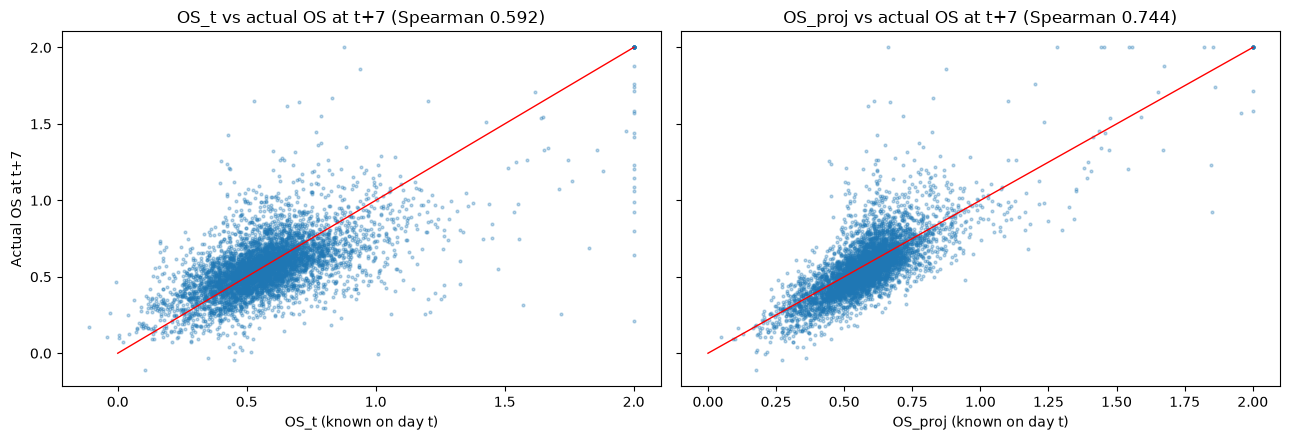

In [66]:
# <Student to fill this section>
rho_proj = data[["OS_proj", "OS_future"]].corr(method="spearman").iloc[0, 1]
rho_t = data[["OS_t", "OS_future"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman with OS at t+7: OS_proj {rho_proj:.3f} vs OS_t {rho_t:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col, rho in [(axes[0], "OS_t", rho_t), (axes[1], "OS_proj", rho_proj)]:
    ax.scatter(data[col].clip(upper=2), data["OS_future"].clip(upper=2), s=4, alpha=0.3)
    ax.plot([0, 2], [0, 2], color="red", linewidth=1)
    ax.set_xlabel(f"{col} (known on day t)")
    ax.set_title(f"{col} vs actual OS at t+7 (Spearman {rho:.3f})")
axes[0].set_ylabel("Actual OS at t+7")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "os_proj_vs_future.png", dpi=150)
plt.show()

In [67]:
# <Student to fill this section>
feature_engineering_n_explanations = """
OS_proj: projected Opportunity Score at t+7, computed on day t.

Idea (forecast-window decomposition): every 20-day window used by the target on day t+7 covers days t-12
to t+7. The first 13 of those 20 days are already known on day t. OS_proj recomputes Return20, MA5/MA20,
Volatility20 and RelativeVolume for day t+7 using the 13 known days exactly, and fills the 7 unknown
days with a 'nothing changes' assumption: price stays at today's close (zero daily returns) and volume
stays at its 20-day average. The projected components are combined with the brief's OS formula and caps.

Leakage check: it only uses data up to day t. Its correctness was verified on test data: when prices
really stay flat for 7 days, OS_proj equals the actual OS at t+7 to six decimal places.

Why it helps: the model no longer has to learn which part of next week's score is already determined;
it only has to learn how the next 7 days are likely to deviate from 'no change'.

Impact: Spearman correlation of 0.744 with OS at t+7 on the full modelling data (0.758 on the
development period used for feature selection), the highest of any feature (OS_t 0.592, Return20 0.575).
The scatter plot shows OS_proj lies much closer to the diagonal than OS_t, especially for typical scores
between 0.25 and 1.0. Adding it raised cross-validated macro F1 from 0.341 to 0.372, the first model to
beat the persistence baseline.

Dependency: it needs the last 20 days of closing prices and volumes per token, which the TOR API already
downloads from Kraken to compute its own volume features, so it creates no new dependency on other APIs.
"""

In [68]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.n Fixing "\<describe_issue_here\>"

> You can add more cells related to new features in this section

---
## G. Data Preparation for Modeling

### G.1 Split Datasets


In [69]:
# <Student to fill this section>
dates = np.sort(data["date"].unique())
VAL_START = pd.Timestamp(dates[int(len(dates) * 0.70)])
TEST_START = pd.Timestamp(dates[int(len(dates) * 0.85)])
GAP = pd.Timedelta(days=FORECAST_HORIZON)

train_df = data[data["date"] < VAL_START - GAP]
val_df = data[(data["date"] >= VAL_START) & (data["date"] < TEST_START - GAP)]
test_df = data[data["date"] >= TEST_START]

X_train, y_train = train_df[features_list], train_df[target_name]
X_val, y_val = val_df[features_list], val_df[target_name]
X_test, y_test = test_df[features_list], test_df[target_name]

split_info = pd.DataFrame({
    "rows": [len(train_df), len(val_df), len(test_df)],
    "start": [d["date"].min().date() for d in (train_df, val_df, test_df)],
    "end": [d["date"].max().date() for d in (train_df, val_df, test_df)],
    "days": [d["date"].nunique() for d in (train_df, val_df, test_df)],
}, index=["train", "val", "test"])
print("Chronological split with a 7-day gap between sets:")
display(split_info)
print(f"Rows dropped in the two 7-day gaps: {len(data) - split_info['rows'].sum()}")

class_split = pd.DataFrame({
    name: (y.value_counts(normalize=True).reindex(range(5), fill_value=0) * 100).round(1)
    for name, y in [("train %", y_train), ("val %", y_val), ("test %", y_test)]
})
class_split.index = TOR_LABELS
class_split["train n"] = y_train.value_counts().reindex(range(5), fill_value=0).values
class_split["val n"] = y_val.value_counts().reindex(range(5), fill_value=0).values
class_split["test n"] = y_test.value_counts().reindex(range(5), fill_value=0).values
print("\nClass distribution per split:")
display(class_split)

Chronological split with a 7-day gap between sets:


,rows,start,end,days
train,3824,2024-11-21,2026-03-13,478
val,776,2026-03-21,2026-06-25,97
test,832,2026-07-03,2026-10-14,104


Rows dropped in the two 7-day gaps: 112

Class distribution per split:


,train %,val %,test %,train n,val n,test n
Strong Sell,2.9,0.0,0.0,111,0,0
Sell,16.4,12.8,4.6,629,99,38
Hold,45.0,50.4,42.8,1721,391,356
Buy,25.9,33.2,37.9,990,258,315
Strong Buy,9.8,3.6,14.8,373,28,123


In [70]:
# <Student to fill this section>
data_splitting_explanations = """
Strategy: chronological split by date, applied to all tokens at once, never shuffled.
  Train:      2024-11-21 to 2026-03-13  (478 days, 3,824 rows, about 70%)
  Validation: 2026-03-21 to 2026-06-25  (97 days, 776 rows, about 15%)
  Test:       2026-07-03 to 2026-10-14  (104 days, 832 rows, about 15%)

Why chronological: the product forecasts the future from the past, so the model must be evaluated on a
period that comes after everything it was trained on. A random split would put days from the same week
into both train and test; because consecutive days share 19 of their 20 days of rolling-window data,
the model would effectively see the answers and the evaluation would be overly optimistic.

Why a 7-day gap: each row's label is computed from day t+7. Without a gap, the last training rows would
have labels inside the validation period (and the last validation rows inside the test period). Seven
days are dropped before validation and before test (112 rows in total) so no label overlaps the next set.

Why all tokens share the same dates: splitting each token separately at the same dates keeps the sets
aligned in time, so the model is never trained on one token's future while being tested on another
token's past during the same market event.

Class distribution and its consequences:
  Strong Sell: train 111 (2.9%), validation 0, test 0
  Sell:        train 16.4%, validation 12.8%, test 4.6%
  Hold:        train 45.0%, validation 50.4%, test 42.8%
  Buy:         train 25.9%, validation 33.2%, test 37.9%
  Strong Buy:  train 9.8%, validation 3.6%, test 14.8%
All Strong Sell days occurred during sell-offs before March 2026, so this class cannot be evaluated
out-of-sample. The test period was a strong market (more Buy and Strong Buy, few Sells), so the class
mix shifts between the sets. This is reported as a limitation rather than corrected, because rearranging
periods to balance the classes would break the time ordering. Macro F1 is therefore computed over the
classes that actually occur or are predicted, so an absent class does not artificially lower the score,
and per-class results are reported alongside it.
"""

In [71]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation "\<put_name_here\>"




In [72]:
# <Student to fill this section>
# Which model features become missing when each sibling API is down.
# RelativeVolume (own feature) and OS_proj (computed from Kraken history) are always available.
OUTAGE_SCENARIOS = {
    "A down (Return20)": ["Return20", "OS_t"],
    "B down (MA5, MA20)": ["MA5", "MA20", "MA_ratio", "OS_t"],
    "C down (Volatility20)": ["Volatility20", "OS_t"],
    "A, B and C down": ["Return20", "MA5", "MA20", "MA_ratio", "Volatility20", "OS_t"],
}


def add_outage_copies(X, y, scenarios=OUTAGE_SCENARIOS):
    """Return X, y plus one copy per outage scenario with the affected features set to NaN."""
    X_parts, y_parts = [X], [y]
    for cols in scenarios.values():
        X_masked = X.copy()
        X_masked[cols] = np.nan
        X_parts.append(X_masked)
        y_parts.append(y)
    return pd.concat(X_parts, ignore_index=True), pd.concat(y_parts, ignore_index=True)


X_train_aug, y_train_aug = add_outage_copies(X_train, y_train)
print(f"Training rows: {len(X_train)} original -> {len(X_train_aug)} with outage copies")
print("\nShare of missing values per feature in the augmented training set:")
print((X_train_aug.isna().mean() * 100).round(1).astype(str).add("%").to_string())

Training rows: 3824 original -> 19120 with outage copies

Share of missing values per feature in the augmented training set:
Return20          40.0%
RelativeVolume     0.0%
Volatility20      40.0%
MA5               40.0%
MA20              40.0%
MA_ratio          40.0%
OS_t              80.0%
OS_proj            0.0%


In [73]:
# <Student to fill this section>
data_transformation_1_explanations = """
Transformation: missing-feature augmentation that simulates outages of the other students' APIs.

Why: in production, the TOR API retrieves Return20 from Student A, MA5 and MA20 from Student B and
Volatility20 from Student C. The brief requires the prediction service to keep working when any of these
services is down, using the available features and missing values. LightGBM supports missing values
natively, but it only learns useful behaviour for them if missing values appear during training. The
historical data has no missing values after cleaning, so a model trained on it alone would never have
seen an outage and could behave unpredictably when one happens.

How: the training set is kept as is, and four extra copies are added, each with the features affected by
one outage scenario set to NaN: A down (Return20, OS_t), B down (MA5, MA20, MA_ratio, OS_t), C down
(Volatility20, OS_t), and all three down. Derived features that depend on a missing input are also set
to missing. RelativeVolume (owned by this service) and OS_proj (computed from Kraken's price and volume
history, which the TOR API downloads itself) stay available in every scenario.

Impact: the training set grows from 3,824 to 19,120 rows, and the model learns, for each scenario, which
of the remaining features to rely on. The augmentation is applied only to training data; validation and
test sets keep their real values. Its effect is measured in section J by evaluating the model with and
without augmentation on simulated outages of the validation set. Because every copy keeps the original
label, the class proportions are unchanged.
"""

In [74]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### G.3 Data Transformation "\<put_name_here\>"

> Add blockquote



In [75]:
# <Student to fill this section>
from sklearn.utils.class_weight import compute_class_weight

classes_present = np.sort(y_train.unique())
balanced = compute_class_weight("balanced", classes=classes_present, y=y_train)
weights_table = pd.DataFrame({
    "train count": y_train.value_counts().reindex(classes_present).values,
    "balanced weight": balanced.round(3),
}, index=[TOR_LABELS[c] for c in classes_present])
print("Balanced class weights = n_samples / (n_classes * class_count):")
display(weights_table)

Balanced class weights = n_samples / (n_classes * class_count):


,train count,balanced weight
Strong Sell,111,6.890
Sell,629,1.216
Hold,1721,0.444
Buy,990,0.773
Strong Buy,373,2.050


In [76]:
# <Student to fill this section>
data_transformation_2_explanations = """
Transformation: class weighting to counter the imbalance in the training set.

Why: Hold makes up 45% of training rows while Strong Sell makes up 2.9% (111 rows). Without weighting,
LightGBM's loss is dominated by Hold, Buy and Sell, and the model can achieve good accuracy while almost
never predicting the extreme classes, which are the most important for users. Balanced weights scale each
row's contribution to the loss by n_samples / (n_classes * class_count), so every class contributes
equally in total: Strong Sell rows weigh about 6.9, Strong Buy about 2.1, Sell about 1.2, Buy about 0.8
and Hold about 0.4.

Trade-off: D.3 showed that balanced weights increase balanced accuracy (0.423 vs 0.396) but reduce
overall accuracy (0.536 vs 0.550), because the model predicts rare classes more often and some of those
predictions are wrong. Neither choice is clearly better for the business, so class weighting (balanced
or none) is included as a hyperparameter in the Optuna search, and the final choice is made on
cross-validated macro F1.

Not applied: feature scaling, normalisation or encoding. LightGBM is a tree-based model that splits on
the order of values, so it is unaffected by feature scale or skewness, and every feature is already
numeric. Avoiding scaling also means the deployed API can feed raw feature values directly to the model.
"""

In [77]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### G.4 Data Transformation "Fixed ordinal label encoding"



In [78]:
# <Student to fill this section>
import json
from at3_crypto.target import LABEL_TO_ID, ID_TO_LABEL

label_map = pd.DataFrame({"class_id": list(ID_TO_LABEL), "label": list(ID_TO_LABEL.values())})
print("Fixed label encoding (ordered from most negative to most positive):")
display(label_map)

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    assert y.between(0, 4).all(), f"{name} has labels outside 0..4"
    print(f"{name:5} class ids present: {sorted(y.unique().tolist())}")

MODELS_DIR.mkdir(parents=True, exist_ok=True)
with open(MODELS_DIR / "tor_label_map.json", "w") as f:
    json.dump({str(k): v for k, v in ID_TO_LABEL.items()}, f, indent=2)
print("\nSaved:", MODELS_DIR / "tor_label_map.json")

Fixed label encoding (ordered from most negative to most positive):


,class_id,label
0,0,Strong Sell
1,1,Sell
2,2,Hold
3,3,Buy
4,4,Strong Buy


train class ids present: [0, 1, 2, 3, 4]
val   class ids present: [1, 2, 3, 4]
test  class ids present: [1, 2, 3, 4]

Saved: C:\dev\36120-at3-group12-experiments\models\tor_label_map.json


In [79]:
# <Student to fill this section>
data_transformation_3_explanations = """
Transformation: a fixed ordinal encoding of the five TOR classes, defined once in at3_crypto/target.py
and saved with the model: 0 = Strong Sell, 1 = Sell, 2 = Hold, 3 = Buy, 4 = Strong Buy.

Why: a classifier learns its list of classes from the labels it sees. In this data Strong Sell appears in
training but not in validation or test, and a future retrain on a different 720-day window could miss a
class altogether. If labels were encoded from whatever values happen to be present, class id 2 could mean
'Hold' in one model and 'Buy' in another, and the API would silently return the wrong recommendation.
Fixing the mapping guarantees that the same id always means the same rating across the notebook, the
saved model and the deployed API.

Why ordinal: the ids follow the natural order of the ratings, from most negative to most positive. This
makes the distance between ids meaningful (|true - predicted|), which is what the within-one-class
accuracy and severe-error-rate metrics in section I rely on.

Impact: the mapping is saved as models/tor_label_map.json, so the API converts the model's class id back
to the correct label, and /model-metadata can list the classification labels the brief requires.
"""

In [80]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

---
## H. Save Datasets


In [81]:
# <Student to fill this section>

data_final_path = '../data/processed'

In [82]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate


In [83]:
# <Student to fill this section>
from sklearn.metrics import classification_report, confusion_matrix


def score_report(y_true, y_pred):
    """Final evaluation metrics. Macro F1 uses the classes present in y_true or y_pred."""
    y_true, y_pred = np.asarray(y_true, dtype=int), np.asarray(y_pred, dtype=int)
    diff = np.abs(y_true - y_pred)
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "accuracy": (diff == 0).mean(),
        "within_one": (diff <= 1).mean(),
        "severe_error_rate": (diff >= 2).mean(),
    }


def show_confusion(y_true, y_pred, title):
    labels = sorted(set(np.asarray(y_true, dtype=int)) | set(np.asarray(y_pred, dtype=int)))
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels),
                      index=[f"true {TOR_LABELS[i]}" for i in labels],
                      columns=[f"pred {TOR_LABELS[i]}" for i in labels])
    print(title)
    display(cm)


# Baselines on the validation set (the test set stays untouched until the final model)
val_baselines = pd.DataFrame({
    "Majority class (Hold)": score_report(y_val, np.full(len(y_val), y_train.mode()[0])),
    "Persistence (today's class)": score_report(y_val, val_df["TOR_t"].astype(int)),
    "Flat-price projection (OS_proj class)": score_report(y_val, val_df["TOR_proj"].astype(int)),
}).T.round(3)
print("Baselines on the validation set:")
display(val_baselines)
show_confusion(y_val, val_df["TOR_proj"].astype(int), "Confusion matrix, flat-price projection (validation):")

Baselines on the validation set:


,macro_f1,balanced_acc,accuracy,within_one,severe_error_rate
Majority class (Hold),0.168,0.250,0.504,0.964,0.036
Persistence (today's class),0.457,0.454,0.552,0.976,0.024
Flat-price projection (OS_proj class),0.507,0.482,0.628,0.982,0.018


Confusion matrix, flat-price projection (validation):


,pred Sell,pred Hold,pred Buy,pred Strong Buy
true Sell,31,63,5,0
true Hold,19,261,111,0
true Buy,0,62,189,7
true Strong Buy,0,9,13,6


In [84]:
# <Student to fill this section>
performance_metrics_explanations = """
Primary metric: macro F1 score. It averages the F1 score of each class with equal weight, so the model
cannot score well by predicting the frequent Hold class and ignoring rare but important classes such as
Strong Buy and Sell. Hold is 45% of training rows, so plain accuracy would reward a model that mostly
predicts Hold. Macro F1 is computed over the classes that occur in the true labels or the predictions.
Strong Sell does not occur in the validation or test periods, so including it automatically would lower
every model's score without telling us anything; if the model wrongly predicts Strong Sell, the class is
still included and penalised. Macro F1 is the objective used for Optuna tuning.

Secondary metrics:
- Balanced accuracy: the average recall per class, showing how well each class is detected.
- Accuracy: the share of exactly correct ratings, the most intuitive number for business users.
- Within-one-class accuracy: the share of predictions at most one class away from the truth (e.g. Hold
  predicted as Buy). The classes are ordered, and neighbouring mistakes are much less harmful to a user
  than distant ones.
- Severe error rate: the share of predictions two or more classes away (e.g. Sell predicted as Buy).
  These are the errors that can lead users into the opposite decision and should be as close to zero as
  possible.
- Confusion matrix and per-class report, to show which classes are confused with which.

Benchmarks: every model is compared with three baselines on the same data: always predicting the
majority class, persistence (next week's class equals today's) and the flat-price projection (class of
OS_proj, no machine learning). A model only adds business value if it beats the strongest of these.
"""

In [85]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit


In [86]:
# <Student to fill this section>
import optuna
from optuna.samplers import TPESampler

print("LightGBM", lgb.__version__, "| Optuna", optuna.__version__)

LightGBM 4.6.0 | Optuna 4.9.0


In [87]:
# <Student to fill this section>
algorithm_selection_explanations = """
Algorithm: LightGBM multiclass classifier (gradient-boosted decision trees with a softmax objective over
the five TOR classes). LightGBM is assigned to Student D by the brief, and it is also well suited to this
problem:

- Non-linear relationships: the EDA showed U-shaped patterns (high volume and high volatility precede
  both Strong Sell and Strong Buy) that a linear model cannot represent but trees capture naturally.
- Skewed features with extreme values: Return20 (skewness 7.85) and RelativeVolume (2.77) contain genuine
  extreme events. Trees split on value order, so no scaling or transformation is needed and outliers do
  not distort the model.
- Native missing-value handling: LightGBM learns a default direction for missing values at every split.
  This is essential for the brief's requirement that predictions continue when other students' APIs are
  down, combined with the outage augmentation in G.2.
- Small tabular data: with about 3,800 training rows and 8 features, gradient-boosted trees are a strong,
  well-established choice; LightGBM trains in seconds, which makes systematic tuning with Optuna feasible.
- Calibrated class probabilities: predict_proba provides the confidence score the API must return.
- Interpretability: split-gain feature importance is available for the /model-metadata endpoint and the
  Streamlit page.

Limitation: LightGBM treats the five classes as unordered categories and does not know that Hold is
closer to Buy than to Strong Sell. This is partly compensated by the ordered engineered features
(OS_t, OS_proj) and by reporting ordinal metrics (within-one-class accuracy, severe error rate).
"""

In [88]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

> Provide some explanations on why you believe this algorithm is a good fit


Best trial: 14. Best value: 0.425144: 100%|██████████| 60/60 [02:41<00:00,  2.68s/it]


Best CV macro F1: 0.425 (std across folds 0.067, trial 14)
Best hyperparameters:
  n_estimators       400
  learning_rate      0.0201
  num_leaves         12
  max_depth          3
  min_child_samples  25
  subsample          0.507
  colsample_bytree   0.7117
  reg_alpha          7.5349
  reg_lambda         7.6574
  class_weight       None

Top 5 trials:


,number,value,params_class_weight,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_alpha,params_reg_lambda,params_subsample
14,14,0.4251,none,0.7117,0.0201,3,25,400,12,7.5349,7.6574,0.5070
25,25,0.4241,none,0.6724,0.0138,4,20,350,14,7.9949,2.8268,0.5642
45,45,0.4237,none,0.6837,0.0264,2,56,400,5,9.5463,6.9343,0.5903
32,32,0.4237,none,0.7332,0.0277,2,20,450,7,8.0868,5.8981,0.5279
21,21,0.4223,none,0.6803,0.0208,2,32,400,10,6.4263,8.5325,0.5033



Hyperparameter importance (fANOVA):
num_leaves           0.308
n_estimators         0.219
reg_alpha            0.138
min_child_samples    0.076
subsample            0.071
learning_rate        0.064
class_weight         0.057
reg_lambda           0.040
colsample_bytree     0.023
max_depth            0.004


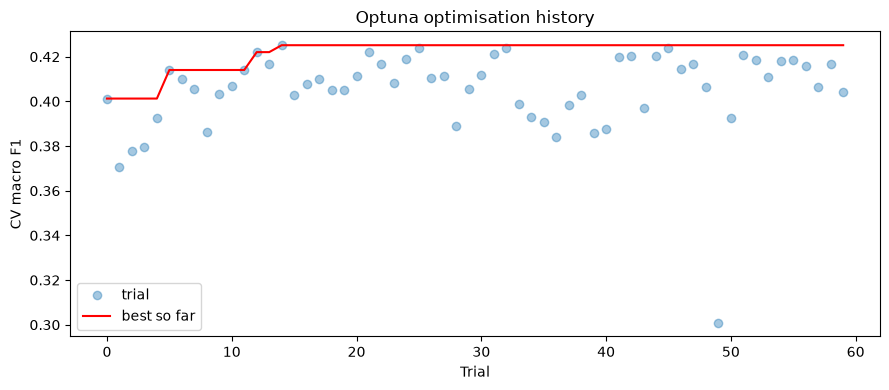

In [89]:
# <Student to fill this section>
N_TRIALS = 60
CV_FOLDS = 4


def make_model(params):
    """LightGBM multiclass classifier with fixed settings plus tuned hyperparameters."""
    return lgb.LGBMClassifier(objective="multiclass", subsample_freq=1, random_state=RANDOM_STATE,
                              n_jobs=N_JOBS, verbose=-1, **params)


def suggest_params(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 600, step=25),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 64, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    params["class_weight"] = trial.suggest_categorical("class_weight", ["balanced", "none"])
    if params["class_weight"] == "none":
        params["class_weight"] = None
    return params


def cv_macro_f1(params, df=train_df, n_folds=CV_FOLDS):
    """Mean macro F1 over expanding-window time-series folds inside the training period."""
    scores = []
    for tr, va in time_folds(df, n_folds=n_folds):
        model = make_model(params).fit(tr[features_list], tr[target_name])
        scores.append(score_report(va[target_name], model.predict(va[features_list]))["macro_f1"])
    return float(np.mean(scores)), float(np.std(scores))


def objective(trial):
    mean_f1, std_f1 = cv_macro_f1(suggest_params(trial))
    trial.set_user_attr("cv_std", std_f1)
    return mean_f1


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_STATE),
                            study_name="tor_lightgbm")
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

best_params = dict(study.best_params)
if best_params["class_weight"] == "none":
    best_params["class_weight"] = None
print(f"\nBest CV macro F1: {study.best_value:.3f} "
      f"(std across folds {study.best_trial.user_attrs['cv_std']:.3f}, trial {study.best_trial.number})")
print("Best hyperparameters:")
for k, v in best_params.items():
    print(f"  {k:18} {round(v, 4) if isinstance(v, float) else v}")

trials_df = study.trials_dataframe(attrs=("number", "value", "params"))
print("\nTop 5 trials:")
display(trials_df.sort_values("value", ascending=False).head(5).round(4))

importances = optuna.importance.get_param_importances(study)
print("\nHyperparameter importance (fANOVA):")
print(pd.Series(importances).round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(trials_df["number"], trials_df["value"], "o", alpha=0.4, label="trial")
ax.plot(trials_df["number"], trials_df["value"].cummax(), color="red", label="best so far")
ax.set_xlabel("Trial"); ax.set_ylabel("CV macro F1"); ax.set_title("Optuna optimisation history")
ax.legend(); plt.tight_layout()
plt.savefig(FIGURES_DIR / "optuna_history.png", dpi=150)
plt.show()

In [90]:
# <Student to fill this section>
hyperparameters_selection_explanations = """
Tuning method: Optuna with the TPE (Bayesian) sampler, 60 trials, fixed seed (42) for reproducibility.
Objective: mean macro F1 over 4 expanding-window time-series folds inside the training period only,
with a 7-day gap between each fold's training and validation data. The validation and test sets are
not used for tuning, so they remain unbiased for model comparison and final evaluation.

Search space (documented as required by the brief):
  n_estimators        50 to 600 (step 25)      number of boosting rounds
  learning_rate       0.01 to 0.2 (log)        shrinkage per tree; lower values generalise better
  num_leaves          4 to 64 (log)            complexity of each tree
  max_depth           2 to 8                   limits tree depth and interaction order
  min_child_samples   10 to 200 (log)          minimum rows per leaf; protects rare classes from noise
  subsample           0.5 to 1.0               share of rows per tree (bagging, every iteration)
  colsample_bytree    0.5 to 1.0               share of features per tree
  reg_alpha           0.001 to 10 (log)        L1 regularisation
  reg_lambda          0.001 to 10 (log)        L2 regularisation
  class_weight        balanced or none         handling of class imbalance (trade-off seen in D.3)
These parameters were chosen because they control the bias-variance trade-off of gradient boosting,
which matters most with a small, noisy dataset of about 3,800 training rows.

Best parameters (trial 14, CV macro F1 0.425, standard deviation across folds 0.067):
  n_estimators 400, learning_rate 0.0201, num_leaves 12, max_depth 3, min_child_samples 25,
  subsample 0.507, colsample_bytree 0.712, reg_alpha 7.535, reg_lambda 7.657, class_weight none.

Interpretation:
- The search converged quickly: the best value was reached at trial 14 and the five best trials lie
  within 0.003 of each other (0.422 to 0.425), indicating a stable optimum rather than a lucky trial.
- All five best trials share the same profile: very shallow trees (max_depth 2 to 4), strong L1 and L2
  regularisation (reg_alpha 6.4 to 9.5), about half the rows per tree and a low learning rate compensated
  by 350 to 450 trees. Seven-day crypto price changes are noisy, so the model generalises best when it is
  constrained to learn only simple, robust patterns. This explains why the unconstrained default model
  overfitted in D.3.
- All five best trials use no class weighting, so the accuracy loss from balanced weights outweighed the
  gain in rare-class recall on macro F1.
- fANOVA importance shows num_leaves (0.31), n_estimators (0.22) and reg_alpha (0.14) mattered most,
  while max_depth (0.004) mattered least once the other complexity limits were set.

Limitation: reg_alpha and reg_lambda of the best trials sit close to the upper bound of the search
space (10), so even stronger regularisation might help slightly; extending the range is a possible
next step. The standard deviation of 0.067 across folds shows that performance depends noticeably on
the market period.
"""

In [91]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.3 Fit Model

In [92]:
# <Student to fill this section>
X_train_aug, y_train_aug = add_outage_copies(X_train, y_train)
DEFAULT_PARAMS = {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 15, "class_weight": "balanced"}

# 1. Same CV folds as Optuna: is the tuned model better than the no-ML baselines?
cv_rows = {}
for name, params in [("Default LightGBM", DEFAULT_PARAMS), ("Tuned LightGBM", best_params)]:
    cv_rows[name] = cv_macro_f1(params)[0]
cv_rows["Flat-price projection (no ML)"] = np.mean([
    score_report(va[target_name], va["TOR_proj"].astype(int))["macro_f1"]
    for _, va in time_folds(train_df, n_folds=CV_FOLDS)])
cv_rows["Persistence (no ML)"] = np.mean([
    score_report(va[target_name], va["TOR_t"].astype(int))["macro_f1"]
    for _, va in time_folds(train_df, n_folds=CV_FOLDS)])
print("Mean CV macro F1 on the 4 training-period folds:")
print(pd.Series(cv_rows).round(3).to_string())

# 2. Fit on the full training set and compare on the validation set
models = {
    "Default LightGBM": make_model(DEFAULT_PARAMS).fit(X_train, y_train),
    "Tuned LightGBM": make_model(best_params).fit(X_train, y_train),
    "Tuned LightGBM + outage augmentation": make_model(best_params).fit(X_train_aug, y_train_aug),
}
val_results = pd.DataFrame({name: score_report(y_val, m.predict(X_val)) for name, m in models.items()}).T
print("\nValidation set (2026-03-21 to 2026-06-25):")
pd.set_option("display.width", 200)
display(pd.concat([val_baselines, val_results]).round(3))

# 3. Robustness: validation set with simulated API outages
rows = []
for scenario, cols in {"No outage": [], **OUTAGE_SCENARIOS}.items():
    X_masked = X_val.copy()
    X_masked[cols] = np.nan
    for name in ["Tuned LightGBM", "Tuned LightGBM + outage augmentation"]:
        s = score_report(y_val, models[name].predict(X_masked))
        rows.append({"scenario": scenario, "model": name, "macro_f1": s["macro_f1"], "accuracy": s["accuracy"]})
robust = pd.DataFrame(rows).pivot(index="scenario", columns="model", values=["macro_f1", "accuracy"])
print("\nValidation performance under simulated API outages:")
display(robust.reindex(["No outage", *OUTAGE_SCENARIOS]).round(3))

Mean CV macro F1 on the 4 training-period folds:
Default LightGBM                 0.374
Tuned LightGBM                   0.425
Flat-price projection (no ML)    0.438
Persistence (no ML)              0.386

Validation set (2026-03-21 to 2026-06-25):


,macro_f1,balanced_acc,accuracy,within_one,severe_error_rate
Majority class (Hold),0.168,0.250,0.504,0.964,0.036
Persistence (today's class),0.457,0.454,0.552,0.976,0.024
Flat-price projection (OS_proj class),0.507,0.482,0.628,0.982,0.018
Default LightGBM,0.353,0.458,0.539,0.950,0.050
Tuned LightGBM,0.413,0.491,0.625,0.985,0.015
Tuned LightGBM + outage augmentation,0.407,0.491,0.628,0.982,0.018



Validation performance under simulated API outages:


macro_f1                                            accuracy                                     
model                 Tuned LightGBM Tuned LightGBM + outage augmentation Tuned LightGBM Tuned LightGBM + outage augmentation
scenario                                                                                                                     
No outage                      0.413                                0.407          0.625                                0.628
A down (Return20)              0.383                                0.407          0.629                                0.629
B down (MA5, MA20)             0.539                                0.401          0.643                                0.635
C down (Volatility20)          0.484                                0.423          0.625                                0.631
A, B and C down                0.421                                0.434          0.608                                0.646

In [93]:
# <Student to fill this section>
preds = {
    "Flat-price projection": val_df["TOR_proj"].astype(int).values,
    "Tuned LightGBM": models["Tuned LightGBM"].predict(X_val),
    "Tuned + augmentation": models["Tuned LightGBM + outage augmentation"].predict(X_val),
}

print("How often each class is predicted on validation (true counts in first row):")
counts = pd.DataFrame({"TRUE": y_val.value_counts().reindex(range(5), fill_value=0)})
for name, p in preds.items():
    counts[name] = pd.Series(p).value_counts().reindex(range(5), fill_value=0).values
counts.index = TOR_LABELS
display(counts)

true_classes = sorted(y_val.unique().tolist())
print("Macro F1 over the 4 classes that actually occur in validation:")
for name, p in preds.items():
    f1_true = f1_score(y_val, p, labels=true_classes, average="macro", zero_division=0)
    print(f"  {name:24} {f1_true:.3f}   (union of true and predicted classes: "
          f"{f1_score(y_val, p, average='macro', zero_division=0):.3f})")

for name in ["Tuned LightGBM", "Tuned + augmentation"]:
    show_confusion(y_val, preds[name], f"\nConfusion matrix, {name} (validation):")

How often each class is predicted on validation (true counts in first row):


,TRUE,Flat-price projection,Tuned LightGBM,Tuned + augmentation
Strong Sell,0,0,3,3
Sell,99,50,58,59
Hold,391,395,424,430
Buy,258,318,272,259
Strong Buy,28,13,19,25


Macro F1 over the 4 classes that actually occur in validation:
  Flat-price projection    0.507   (union of true and predicted classes: 0.507)
  Tuned LightGBM           0.516   (union of true and predicted classes: 0.413)
  Tuned + augmentation     0.509   (union of true and predicted classes: 0.407)

Confusion matrix, Tuned LightGBM (validation):


,pred Strong Sell,pred Sell,pred Hold,pred Buy,pred Strong Buy
true Strong Sell,0,0,0,0,0
true Sell,3,36,60,0,0
true Hold,0,22,274,93,2
true Buy,0,0,80,168,10
true Strong Buy,0,0,10,11,7



Confusion matrix, Tuned + augmentation (validation):


,pred Strong Sell,pred Sell,pred Hold,pred Buy,pred Strong Buy
true Strong Sell,0,0,0,0,0
true Sell,3,36,60,0,0
true Hold,0,23,280,83,5
true Buy,0,0,81,164,13
true Strong Buy,0,0,9,12,7


### J.4 Model Technical Performance

> Add blockquote



> Provide some explanations on model performance


Final model trained on 2024-11-21 to 2026-06-25: 4656 rows (23280 with outage copies)

Test set (2026-07-03 to 2026-10-14, 832 rows):


,macro_f1,balanced_acc,accuracy,within_one,severe_error_rate,macro_f1_true_classes
Majority class (Hold),0.150,0.250,0.428,0.852,0.148,0.150
Persistence (today's class),0.451,0.443,0.547,0.929,0.071,0.451
Flat-price projection (OS_proj class),0.427,0.418,0.583,0.974,0.026,0.427
Tuned LightGBM + outage augmentation,0.497,0.467,0.611,0.966,0.034,0.497



Confusion matrix, final model (test):


,pred Sell,pred Hold,pred Buy,pred Strong Buy
true Sell,8,30,0,0
true Hold,7,267,82,0
true Buy,2,107,199,7
true Strong Buy,0,26,63,34



Per-class report (test):
              precision    recall  f1-score   support

        Sell       0.47      0.21      0.29        38
        Hold       0.62      0.75      0.68       356
         Buy       0.58      0.63      0.60       315
  Strong Buy       0.83      0.28      0.41       123

    accuracy                           0.61       832
   macro avg       0.62      0.47      0.50       832
weighted avg       0.63      0.61      0.59       832

Accuracy by confidence band (test):


,predictions,accuracy
band,,
"(-0.001, 0.5]",151,0.583
"(0.5, 0.6]",285,0.586
"(0.6, 0.7]",200,0.610
"(0.7, 0.8]",156,0.647
"(0.8, 1.0]",40,0.750


Feature importance (share of total gain):
OS_proj           0.746
MA_ratio          0.071
Return20          0.051
Volatility20      0.046
RelativeVolume    0.035
MA20              0.025
MA5               0.025
OS_t              0.001


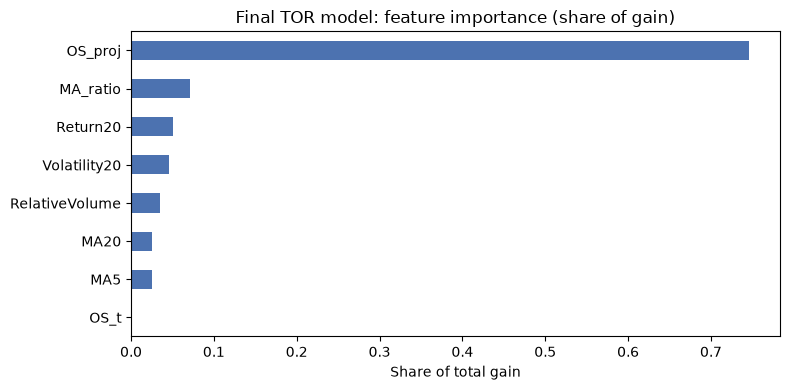

In [94]:
# <Student to fill this section>
FINAL_NAME = "Tuned LightGBM + outage augmentation"

# 1. Refit on all data before the test period (train + gap + validation), with outage copies
final_train = data[data["date"] < TEST_START - GAP]
X_final, y_final = add_outage_copies(final_train[features_list], final_train[target_name])
final_model = make_model(best_params).fit(X_final, y_final)
print(f"Final model trained on {final_train['date'].min().date()} to {final_train['date'].max().date()}: "
      f"{len(final_train)} rows ({len(X_final)} with outage copies)")

# 2. One-time evaluation on the untouched test set
test_pred = final_model.predict(X_test)
test_proba = final_model.predict_proba(X_test)
test_true_classes = sorted(y_test.unique().tolist())

test_table = pd.DataFrame({
    "Majority class (Hold)": score_report(y_test, np.full(len(y_test), y_train.mode()[0])),
    "Persistence (today's class)": score_report(y_test, test_df["TOR_t"].astype(int)),
    "Flat-price projection (OS_proj class)": score_report(y_test, test_df["TOR_proj"].astype(int)),
    FINAL_NAME: score_report(y_test, test_pred),
}).T
test_table["macro_f1_true_classes"] = [
    f1_score(y_test, p, labels=test_true_classes, average="macro", zero_division=0)
    for p in [np.full(len(y_test), y_train.mode()[0]), test_df["TOR_t"].astype(int),
              test_df["TOR_proj"].astype(int), test_pred]]
print(f"\nTest set ({test_df['date'].min().date()} to {test_df['date'].max().date()}, {len(test_df)} rows):")
pd.set_option("display.width", 220)
display(test_table.round(3))

show_confusion(y_test, test_pred, "\nConfusion matrix, final model (test):")
present = sorted(set(y_test) | set(test_pred))
print("\nPer-class report (test):")
print(classification_report(y_test, test_pred, labels=present,
                            target_names=[TOR_LABELS[i] for i in present], zero_division=0))

# 3. Does the confidence score mean something? Accuracy by confidence band
conf = test_proba.max(axis=1)
bands = pd.cut(conf, bins=[0, 0.5, 0.6, 0.7, 0.8, 1.0], include_lowest=True)
conf_table = (pd.DataFrame({"correct": test_pred == y_test.values, "band": bands})
              .groupby("band", observed=True)["correct"].agg(["count", "mean"]))
conf_table.columns = ["predictions", "accuracy"]
print("Accuracy by confidence band (test):")
display(conf_table.round(3))

# 4. Feature importance (share of total split gain)
gain = pd.Series(final_model.booster_.feature_importance(importance_type="gain"), index=features_list)
feature_importance = (gain / gain.sum()).sort_values(ascending=False)
print("Feature importance (share of total gain):")
print(feature_importance.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
feature_importance.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Final TOR model: feature importance (share of gain)")
ax.set_xlabel("Share of total gain")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_feature_importance.png", dpi=150)
plt.show()

In [95]:
# <Student to fill this section>
import joblib
from datetime import datetime, timezone

EXPERIMENT_DIR = MODELS_DIR / student_id / "experiment_1"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

model_path = EXPERIMENT_DIR / "tor_lgbm.joblib"
joblib.dump(final_model, model_path)

metadata = {
    "target": "Trading Opportunity Rating (TOR)",
    "target_description": ("5-class rating of a cryptocurrency's Opportunity Score 7 days ahead, "
                           "OS = 0.40*M + 0.30*T + 0.20*V - 0.10*R"),
    "algorithm": "LightGBM Classifier",
    "forecast_horizon": FORECAST_HORIZON,
    "features": features_list,
    "feature_importance": {k: round(float(v), 4) for k, v in feature_importance.items()},
    "classification_labels": {str(k): v for k, v in ID_TO_LABEL.items()},
    "hyperparameters": best_params,
    "training_period": [str(final_train["date"].min().date()), str(final_train["date"].max().date())],
    "training_rows": int(len(final_train)),
    "outage_augmentation": OUTAGE_SCENARIOS,
    "test_metrics": {k: round(float(v), 4) for k, v in test_table.loc[FINAL_NAME].items()},
    "data_source": "Kraken public OHLC API, daily candles",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "library_versions": {"lightgbm": lgb.__version__, "scikit-learn": sklearn.__version__,
                         "pandas": pd.__version__},
}
with open(EXPERIMENT_DIR / "tor_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Reload check: the saved model gives identical predictions
reloaded = joblib.load(model_path)
assert (reloaded.predict(X_test) == test_pred).all()
print("Saved and verified:")
for p in sorted(EXPERIMENT_DIR.iterdir()):
    print(f"  {p.relative_to(MODELS_DIR.parent)}  ({p.stat().st_size / 1024:.1f} KB)")

Saved and verified:
  models\26059271\experiment_1\tor_lgbm.joblib  (1723.9 KB)
  models\26059271\experiment_1\tor_metadata.json  (2.0 KB)


In [96]:
# <Student to fill this section>
model_performance_explanations = """
Final model: LightGBM classifier with the Optuna-tuned hyperparameters, trained with outage augmentation
on all data before the test period (2024-11-21 to 2026-06-25, 4,656 rows, 23,280 with outage copies),
then evaluated once on the untouched test set (2026-07-03 to 2026-10-14, 832 rows).

Test results (macro F1 / balanced accuracy / accuracy / within-one / severe error rate):
  Majority class (Hold)          0.150 / 0.250 / 0.428 / 0.852 / 0.148
  Persistence (today's class)    0.451 / 0.443 / 0.547 / 0.929 / 0.071
  Flat-price projection (no ML)  0.427 / 0.418 / 0.583 / 0.974 / 0.026
  Final LightGBM model           0.497 / 0.467 / 0.611 / 0.966 / 0.034

1. The model beats all three baselines on the main metrics: macro F1 is 0.046 higher than persistence
   and 0.070 higher than the flat-price projection, and accuracy is 61.1% against 54.7% and 58.3%.
   On validation the tuned model only matched the projection (0.516 vs 0.507 on the classes present), so
   its advantage is not uniform across periods but holds on the final, unseen data.
2. Generalisation: performance is consistent across CV (0.425), validation (0.509 on present classes)
   and test (0.497), so there is no sign of overfitting to the tuning folds.
3. Per class: Hold is predicted best (recall 0.75, F1 0.68), followed by Buy (F1 0.60). The model is
   conservative at the extremes: when it predicts Strong Buy it is right 83% of the time, but it only
   identifies 28% of Strong Buy days, and it identifies 21% of Sell days. It never predicted Strong Sell
   on the test period, which contains no Strong Sell days. Strong Sell performance therefore cannot be
   evaluated out-of-sample (see G.1).
4. Error severity: 96.6% of predictions are correct or one class away. The severe error rate (3.4%) is
   slightly higher than the projection's (2.6%), almost entirely due to 26 Strong Buy days predicted as
   Hold, which are missed opportunities rather than harmful calls. Only 2 of 832 predictions pointed in
   the opposite direction (Buy predicted as Sell), and no Sell day was predicted as Buy or Strong Buy.
5. Confidence: accuracy rises with the predicted probability, from 58% for confidence below 0.5 to 65%
   for 0.7 to 0.8 and 75% above 0.8, so the confidence score returned by the API is meaningful and
   helps users decide how much to rely on a rating.
6. Feature importance: OS_proj accounts for 75% of the total split gain, followed by MA_ratio (7%),
   Return20 (5%), Volatility20 (5%) and RelativeVolume (3.5%). OS_t contributes almost nothing (0.1%):
   its information is already contained in OS_proj, and it is missing in 80% of the augmented training
   rows. The model works mainly by correcting the 'nothing changes' projection with momentum, trend,
   volatility and volume signals.

Limitations: results come from a single 15-week test period that was mostly bullish (52.7% Buy or
Strong Buy), so performance in a sustained downturn is untested; recall for the extreme classes is low.
"""

In [97]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view


In [98]:
# <Student to fill this section>
fwd = df_tor[["token", "date", "close"]].copy()
fwd["fwd_return_7d"] = fwd.groupby("token")["close"].shift(-FORECAST_HORIZON) / fwd["close"] - 1
test_eval = test_df[["token", "date", target_name]].merge(fwd[["token", "date", "fwd_return_7d"]],
                                                         on=["token", "date"], how="left")
test_eval["predicted"] = [TOR_LABELS[i] for i in test_pred]
test_eval["confidence"] = test_proba.max(axis=1)

print("Actual 7-day price return after each predicted rating (test period):")
by_pred = test_eval.groupby("predicted")["fwd_return_7d"].agg(["count", "mean", "median",
                                                               lambda s: (s > 0).mean()])
by_pred.columns = ["predictions", "mean return", "median return", "share positive"]
display(by_pred.reindex([l for l in TOR_LABELS if l in by_pred.index]).round(4))

print(f"Average 7-day return across all test rows: {test_eval['fwd_return_7d'].mean():.4f}")

high = test_eval[test_eval["confidence"] >= 0.7]
print(f"\nHigh-confidence predictions (>= 0.7): {len(high)} of {len(test_eval)}")
display(high.groupby("predicted")["fwd_return_7d"].agg(["count", "mean"]).round(4))

err = pd.crosstab(pd.Series([TOR_LABELS[i] for i in y_test], name="true"),
                  pd.Series(test_eval["predicted"].values, name="predicted"))
print("\nCostly error types (test):")
print(f"  Predicted Buy/Strong Buy, actually Sell/Strong Sell: "
      f"{int(((test_pred >= 3) & (y_test.values <= 1)).sum())}")
print(f"  Predicted Sell/Strong Sell, actually Buy/Strong Buy: "
      f"{int(((test_pred <= 1) & (y_test.values >= 3)).sum())}")
print(f"  Missed Strong Buy (predicted Hold or lower):          "
      f"{int(((y_test.values == 4) & (test_pred <= 2)).sum())}")

Actual 7-day price return after each predicted rating (test period):


,predictions,mean return,median return,share positive
predicted,,,,
Sell,17,-0.0304,-0.0349,0.2353
Hold,430,0.0165,-0.0043,0.4651
Buy,344,0.0215,0.0067,0.5756
Strong Buy,41,-0.0038,-0.0104,0.3902


Average 7-day return across all test rows: 0.0166

High-confidence predictions (>= 0.7): 196 of 832


,count,mean
predicted,,
Buy,37,0.0081
Hold,145,0.0320
Sell,1,-0.0327
Strong Buy,13,-0.0368



Costly error types (test):
  Predicted Buy/Strong Buy, actually Sell/Strong Sell: 0
  Predicted Sell/Strong Sell, actually Buy/Strong Buy: 2
  Missed Strong Buy (predicted Hold or lower):          26


In [99]:
# <Student to fill this section>
business_impacts_explanations = """
Interpretation against the business objectives:
1. Objective 2 (beat simple baselines) is met on the test set: macro F1 0.497 vs 0.451 (persistence) and
   0.427 (flat-price projection), accuracy 61.1% vs 54.7% and 58.3%.
2. Objective 3 (meaningful confidence) is met: accuracy rises from 58% for confidence below 0.5 to 75%
   above 0.8, so the confidence score helps users judge how much to trust a rating.
3. Objective 4 (robustness) is met: with outage augmentation the model kept 64.6% validation accuracy
   when all three sibling APIs were simulated as unavailable.

What the ratings meant for users in the test period (actual price change over the following 7 days):
  Predicted Sell (17):        mean -3.0%, price rose in only 24% of cases
  Predicted Hold (430):       mean +1.7%, rose in 47%
  Predicted Buy (344):        mean +2.2%, rose in 58%
  Predicted Strong Buy (41):  mean -0.4%, rose in 39%
  All test rows:              mean +1.7%
Sell predictions were a useful warning and Buy predictions were mildly favourable. Strong Buy predictions,
however, were followed by slightly negative returns (high-confidence Strong Buy: -3.7% over 13 cases).

Why: the TOR rating is driven mostly by 20-day momentum at t+7, and 13 of those 20 days are already in the
past on the day of the prediction. A Strong Buy therefore largely signals that recent weeks were very
strong, which often coincides with the end of a rally, when prices tend to pull back. The model predicts
the rating well (Strong Buy precision 83%), but the rating describes momentum, not future returns.

Cost of incorrect results (test set, 832 predictions):
- Most harmful error, Buy or Strong Buy predicted when the outcome was Sell or Strong Sell: 0 cases.
- Opposite error, Sell predicted when the outcome was Buy or Strong Buy: 2 cases (missed upside, low cost).
- Missed Strong Buy (predicted Hold or lower): 26 cases. Given the returns above, the cost of these misses
  to users was limited.
- Wrong Hold vs Buy decisions (one class away) make up most errors and have a small impact, because the
  average returns after Hold and Buy differ by only about 0.5 percentage points.

Business implications: the product should present TOR as a momentum-based market condition indicator,
not as a buy or sell instruction, with a clear general-advice disclaimer (relevant to ASIC rules). Strong
Buy in particular should be explained as 'strong recent momentum, with elevated pull-back risk', so that
inexperienced users do not chase rallies at their peak. These results come from a single, mostly bullish
15-week period with small samples for the extreme classes (41 Strong Buy, 17 Sell), and consecutive days
overlap in their 7-day outcomes, so they are indicative rather than statistically conclusive.
"""

In [100]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

## H. Project Outcomes


In [101]:
# <Student to fill this section>
experiment_outcome = "Hypothesis Partially Confirmed"

In [102]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [103]:
# <Student to fill this section>
experiment_results_explanations = """
Hypothesis: a LightGBM classifier tuned with Optuna can predict the Trading Opportunity Rating 7 days
ahead more accurately than simple baselines, using the brief's engineered features from other services,
and can keep working when those services are unavailable.

Outcome: partially confirmed.
- Confirmed: the final model beats the majority, persistence and flat-price projection baselines on the
  untouched test set (macro F1 0.497 vs 0.451 and 0.427; accuracy 61.1% vs 54.7% and 58.3%), with 96.6%
  of predictions correct or one class away, a meaningful confidence score, and robustness to API outages.
- Not confirmed: the advantage over the projection baseline is not uniform (on validation the model only
  matched it), Strong Sell could not be evaluated because it does not occur after March 2026, recall for
  the extreme classes is low (Sell 21%, Strong Buy 28%), and the Strong Buy rating, as defined by the
  brief, was not followed by positive returns in the test period.

Key insights:
1. Most of next week's rating is already determined today: 13 of the 20 days in every future window are
   known. Making this explicit with the engineered feature OS_proj was the single most effective decision
   (Spearman 0.744 with the future score, 75% of the model's split gain).
2. Seven-day crypto movements are noisy: the best models were shallow and heavily regularised, and a
   simple 'nothing changes' projection is a strong baseline that any model must be compared against.
3. Scale-free features are essential when pooling assets with prices from 0.17 to 90,000 USD.
4. Accuracy metrics alone can be misleading: three wrong Strong Sell predictions reduced validation
   macro F1 by 0.1, and a well-predicted Strong Buy rating still had poor financial value.

Next steps, ranked by expected gain:
1. High: redefine or complement the target with forward-looking returns (e.g. the 7-day return or a
   risk-adjusted return) so the rating reflects future opportunity rather than past momentum. This
   addresses the main business weakness found in J.5.
2. High: retrain regularly (e.g. weekly) on the newest 720 days, since Kraken's window moves forward and
   market regimes change; monitor live accuracy and the class mix.
3. Medium: add more history (the provided dataset or another API with older data) so the model sees more
   market regimes, including sustained downturns and Strong Sell periods.
4. Medium: model the problem as ordinal (e.g. regression on OS_future then binning, or ordinal
   thresholds) so the model knows Hold is closer to Buy than to Strong Sell, which should reduce severe
   errors.
5. Low: widen the Optuna search for regularisation (best values sit near the upper bound of 10) and
   tune the decision thresholds per class to raise recall for Sell and Strong Buy.

Deployment recommendation: the model is suitable for deployment as a decision-support indicator, not as
trading advice. The saved model and metadata (models/<student_id>/experiment_1) are loaded by the TOR
FastAPI service, which retrieves price and volume history from Kraken, requests Return20, MA5, MA20 and
Volatility20 from the sibling APIs (using missing values if any are down), computes the engineered
features with the same code as this notebook, and returns the rating, confidence and feature importance.
The Streamlit page should show the confidence and a general-advice disclaimer, and explain Strong Buy
as strong recent momentum with pull-back risk.
"""

In [104]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)